# 05 Model Scientific Interest

Canonical modeling notebook for yearly scientific interest.
This notebook computes SI, ranks future high-interest pathogen-antibiotic pairs, and generates focused plots.
Set `ANTIBIOTIC_ANALYSIS_LEVEL` to `"antibiotic"` for individual antibiotics, or to a column in `assets/antibiotic_coarsening_lookup.csv` such as `"Class"`.


In [58]:
%load_ext autoreload
%autoreload 2


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [59]:
from pathlib import Path
import sys

from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "amr").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "amr").exists():
    raise RuntimeError(f"Could not find repository root from {Path.cwd()}")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from amr.pipelines.si import (
    DEFAULT_DRIVER_SUMMARY_COLUMNS,
    DEFAULT_DECREASING_SI_SUMMARY_COLUMNS,
    DEFAULT_SMOOTHED_SI_SHAPE_SUMMARY_COLUMNS,
    DEFAULT_INTERESTING_SUMMARY_COLUMNS,
    build_si_analysis_paths,
    build_si_driver_analysis,
    build_yearly_si_dataset,
    filter_model_inputs_by_average_amr_publications,
    load_yearly_si_inputs,
    prepare_antibiotic_analysis_level,
    print_si_dataset_summary,
    rank_future_high_interest_pairs,
    save_category_driver_plots,
    save_category_driver_pie_grid,
    save_interesting_si_plots,
    save_smoothed_si_screen_plots,
    select_existing_columns,
    summarize_smoothed_si_shapes,
    select_smoothed_si_shape_cases,
    select_decreasing_smoothed_si_trends,
    summarize_pair_publication_rates,
    summarize_pathogen_coverage,
)
from amr.pipeline_config import cfg, cfg_path, load_pipeline_config


## Configuration


In [60]:
PIPELINE_CONFIG = load_pipeline_config(project_root=PROJECT_ROOT)

OUTPUT_DIR = cfg_path(PIPELINE_CONFIG, "paths.output_dir", PROJECT_ROOT)
PARQUET_OUTPUT_DIR = cfg_path(PIPELINE_CONFIG, "paths.parquet_dir", PROJECT_ROOT)
PARQUET_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
DATA_DIR = PARQUET_OUTPUT_DIR

YEARLY_SCREENED_PATH = cfg_path(PIPELINE_CONFIG, "paths.yearly_screened", PROJECT_ROOT)
UNIFIED_DECISIONS_PATH = cfg_path(PIPELINE_CONFIG, "paths.unified_decisions", PROJECT_ROOT)
PATHOGEN_BG_PATH = cfg_path(PIPELINE_CONFIG, "paths.pathogen_background", PROJECT_ROOT)
ANTIBIOTIC_BG_PATH = cfg_path(PIPELINE_CONFIG, "paths.antibiotic_background", PROJECT_ROOT)
ANTIBIOTIC_COARSENING_PATH = cfg_path(PIPELINE_CONFIG, "paths.antibiotic_coarsening", PROJECT_ROOT)
DRIVER_CATEGORY_COARSENING_PATH = cfg_path(PIPELINE_CONFIG, "paths.driver_category_coarsening", PROJECT_ROOT)

# Analysis level controls antibiotic grouping for all SI model inputs and outputs.
ANTIBIOTIC_ANALYSIS_LEVEL = cfg(PIPELINE_CONFIG, "si.antibiotic_analysis_level")
SI_PATHS = build_si_analysis_paths(PROJECT_ROOT, ANTIBIOTIC_ANALYSIS_LEVEL)
YEARLY_SI_PATH = SI_PATHS["yearly_si"]
RANK_OUTPUT_PATH = SI_PATHS["rank_output"]
INTERESTING_OUTPUT_PATH = SI_PATHS["interesting_output"]
DRIVER_OUTPUT_PATH = SI_PATHS["driver_output"]
INTERESTING_PLOT_DIR = SI_PATHS["interesting_plot_dir"]
DRIVER_PLOT_DIR = SI_PATHS["driver_plot_dir"]
DECREASING_SI_OUTPUT_PATH = PARQUET_OUTPUT_DIR / "decreasing_smoothed_si_trends.parquet"
CONVEX_SI_OUTPUT_PATH = PARQUET_OUTPUT_DIR / "convex_u_shaped_smoothed_si_trends.parquet"
CONCAVE_SI_OUTPUT_PATH = PARQUET_OUTPUT_DIR / "concave_inverted_u_smoothed_si_trends.parquet"
DECREASING_SI_PLOT_DIR = OUTPUT_DIR / "figures" / "decreasing_smoothed_si_plots"
CONVEX_SI_PLOT_DIR = OUTPUT_DIR / "figures" / "convex_u_shaped_smoothed_si_plots"
CONCAVE_SI_PLOT_DIR = OUTPUT_DIR / "figures" / "concave_inverted_u_smoothed_si_plots"

# Fit/rank window controls.
FIT_START_YEAR = cfg(PIPELINE_CONFIG, "si.fit_start_year")
FIT_END_YEAR = cfg(PIPELINE_CONFIG, "si.fit_end_year")
CURVE_FIT_END_YEAR = cfg(PIPELINE_CONFIG, "si.curve_fit_end_year")
NUM_FUTURE_YEARS = cfg(PIPELINE_CONFIG, "si.num_future_years")
PLOT_END_YEAR = CURVE_FIT_END_YEAR + NUM_FUTURE_YEARS

# Pair filtering and interesting-pair ranking thresholds.
MIN_TOTAL_AMR_PUBLICATIONS = cfg(PIPELINE_CONFIG, "si.min_tot_amr_publications")
MIN_CURRENT_PREDICTED_COUNT = cfg(PIPELINE_CONFIG, "si.min_current_predicted_count")
MIN_FUTURE_PREDICTED_COUNT = cfg(PIPELINE_CONFIG, "si.min_future_predicted_count")
MIN_SI_CHANGE = cfg(PIPELINE_CONFIG, "si.min_si_change")
MIN_POST_FIT_OBSERVED_YEARS = cfg(PIPELINE_CONFIG, "si.min_post_fit_observed_years")
MAX_POST_FIT_SI_ABS_PCT_ERROR_MEAN = cfg(PIPELINE_CONFIG, "si.max_post_fit_si_abs_pct_error_mean")
MAX_SI_LOESS_RESIDUAL_VARIANCE_MEAN = cfg(PIPELINE_CONFIG, "si.max_si_loess_residual_variance_mean")
FALLBACK_TOP_N = cfg(PIPELINE_CONFIG, "si.fallback_top_n")

# Driver plots and display controls.
CATEGORY_INCLUDE_DECISIONS = tuple(cfg(PIPELINE_CONFIG, "si.category_include_decisions"))
DRIVER_CATEGORY_LEVEL = cfg(PIPELINE_CONFIG, "si.driver_category_level")
DRIVER_LOOKBACK_YEARS = cfg(PIPELINE_CONFIG, "si.driver_lookback_years")
MAX_DRIVER_PLOTS = cfg(PIPELINE_CONFIG, "si.max_driver_plots")
DRIVER_PIE_GRID_COLUMNS = cfg(PIPELINE_CONFIG, "si.driver_pie_grid_columns")
MAX_INTERESTING_PLOTS = cfg(PIPELINE_CONFIG, "si.max_interesting_plots")
FIGURE_FORMAT = cfg(PIPELINE_CONFIG, "si.figure_format")
DISPLAY_PLOTS = cfg(PIPELINE_CONFIG, "si.display_plots")
MAX_DISPLAY_PLOTS = cfg(PIPELINE_CONFIG, "si.max_display_plots")
FILL_MISSING_AMR_COUNTS_WITH_ZERO = cfg(PIPELINE_CONFIG, "si.fill_missing_amr_counts_with_zero")
LOESS_FRAC = cfg(PIPELINE_CONFIG, "si.loess_frac")
LOESS_DEGREE = cfg(PIPELINE_CONFIG, "si.loess_degree")
TAIL_DAMPING_YEARS = cfg(PIPELINE_CONFIG, "si.tail_damping_years")
SHAPE_SCREEN_PLOT_COUNT = cfg(PIPELINE_CONFIG, "si.shape_screen_plot_count")


## Load Canonical Inputs


In [61]:
yearly_screened_df, pathogen_bg_df, antibiotic_bg_df, unified_decisions_df = load_yearly_si_inputs(
    yearly_screened_path=YEARLY_SCREENED_PATH,
    pathogen_background_path=PATHOGEN_BG_PATH,
    antibiotic_background_path=ANTIBIOTIC_BG_PATH,
    unified_decisions_path=UNIFIED_DECISIONS_PATH,
)


yearly_screened rows: 19,322
yearly_screened unique pathogens: 48
yearly_screened unique antibiotics: 196
yearly_screened year range: 2000 - 2026
pathogen bg rows: 1,296
antibiotic bg rows: 5,319
unified decision rows available for driver analysis: 161,140


## Prepare Antibiotic Analysis Level

This step optionally aggregates from individual antibiotics to a selected coarsening column before SI modeling.


In [62]:
yearly_screened_model_df, antibiotic_bg_model_df, unified_decisions_model_df, analysis_summary = prepare_antibiotic_analysis_level(
    yearly_screened_df=yearly_screened_df,
    antibiotic_background_df=antibiotic_bg_df,
    unified_decisions_df=unified_decisions_df,
    coarsening_path=ANTIBIOTIC_COARSENING_PATH,
    analysis_level=ANTIBIOTIC_ANALYSIS_LEVEL,
)

yearly_screened_model_df.head(10)


Antibiotic analysis level: individual antibiotic.
model yearly rows: 19,322
model pathogen-antibiotic rows: 2,685
model antibiotic values: 196
model antibiotic background rows: 5,319
model unified decision rows: 161,140


,pathogen,antibiotic,year,pmids,count
0,Acinetobacter baumannii,Amikacin,2003,"[12872781, 14748260]",2
1,Acinetobacter baumannii,Amikacin,2005,"[16103700, 16258323]",2
2,Acinetobacter baumannii,Amikacin,2006,"[16597632, 16776825]",2
3,Acinetobacter baumannii,Amikacin,2008,"[18261233, 18792817]",2
4,Acinetobacter baumannii,Amikacin,2009,[19795613],1
5,Acinetobacter baumannii,Amikacin,2010,"[20107089, 20194701, 20499531, 20921306, 21137...",5
6,Acinetobacter baumannii,Amikacin,2011,[22016680],1
7,Acinetobacter baumannii,Amikacin,2012,"[22104303, 22154196, 22461312, 22579564, 22808...",6
8,Acinetobacter baumannii,Amikacin,2013,"[23400749, 23435692, 23660097, 23668462, 23676...",9
9,Acinetobacter baumannii,Amikacin,2014,"[24235096, 24607428, 24653812, 25241558, 25336...",6


## Build Yearly SI Dataset


## Filter Low-Volume Pairs

Keep only pathogen-antibiotic pairs with enough screened AMR publications on average across the fitting window. The average includes years with zero publications.


In [63]:
yearly_screened_model_unfiltered_df = yearly_screened_model_df.copy()

yearly_screened_model_df, unified_decisions_model_df, pair_publication_rates = filter_model_inputs_by_average_amr_publications(
    yearly_screened_model_df=yearly_screened_model_df,
    unified_decisions_model_df=unified_decisions_model_df,
    fit_start_year=FIT_START_YEAR,
    fit_end_year=FIT_END_YEAR,
    min_total_amr_publications=MIN_TOTAL_AMR_PUBLICATIONS,
)

pathogen_filter_summary_df = summarize_pathogen_coverage(
    source_df=yearly_screened_model_unfiltered_df,
    modeled_df=yearly_screened_model_df,
    source_label="model input before publication filter",
    modeled_label="model input after publication filter",
)

display(pathogen_filter_summary_df.query("status != 'present_in_both'"))
summarize_pair_publication_rates(pair_publication_rates, head=30)


AMR publication filter: kept 94 / 2,685 pairs with >= 100 total publications from 2000 to 2023.
model input before publication filter pathogens: 48
model input after publication filter pathogens: 17
Pathogens present in model input before publication filter but absent from model input after publication filter: 31
Aggregatibacter actinomycetemcomitans, Bacillus anthracis, Bordetella pertussis, Borrelia burgdorferi, Brucella melitensis, Burkholderia cepacia, Burkholderia pseudomallei, Chlamydia pneumoniae, Chlamydia trachomatis, Clostridium perfringens, Coxiella burnetii, Cutibacterium acnes, Francisella tularensis, Legionella pneumophila, Listeria monocytogenes, Moraxella catarrhalis, Mycobacterium abscessus, Mycobacterium avium, Mycobacterium leprae, Mycoplasmoides pneumoniae, Neisseria meningitidis, Orientia tsutsugamushi, Porphyromonas gingivalis, Shigella flexneri, Stenotrophomonas maltophilia, Streptococcus pyogenes, Treponema pallidum, Vibrio cholerae, Vibrio parahaemolyticus, Yer

,pathogen,source_rows,source_publications,source_pairs,modeled_rows,modeled_publications,modeled_pairs,in_source,in_modeled,status
0,Aggregatibacter actinomycetemcomitans,77,26,19,0.0,0.0,0.0,True,False,missing_from_modeled
1,Bacillus anthracis,47,31,31,0.0,0.0,0.0,True,False,missing_from_modeled
2,Bordetella pertussis,65,62,23,0.0,0.0,0.0,True,False,missing_from_modeled
3,Borrelia burgdorferi,24,14,16,0.0,0.0,0.0,True,False,missing_from_modeled
4,Brucella melitensis,112,83,30,0.0,0.0,0.0,True,False,missing_from_modeled
5,Burkholderia cepacia,182,97,42,0.0,0.0,0.0,True,False,missing_from_modeled
6,Burkholderia pseudomallei,131,95,35,0.0,0.0,0.0,True,False,missing_from_modeled
7,Chlamydia pneumoniae,29,8,20,0.0,0.0,0.0,True,False,missing_from_modeled
8,Chlamydia trachomatis,90,28,31,0.0,0.0,0.0,True,False,missing_from_modeled
9,Clostridium perfringens,254,158,65,0.0,0.0,0.0,True,False,missing_from_modeled


,pathogen,antibiotic,fit_window_amr_publications,avg_amr_publications_per_year
1884,Staphylococcus aureus,Meticillin,2875,119.791667
719,Escherichia coli,Ampicillin,984,41.000000
1939,Staphylococcus aureus,Vancomycin,706,29.416667
864,Escherichia coli,Tetracycline,661,27.541667
767,Escherichia coli,Ciprofloxacin,645,26.875000
983,Helicobacter pylori,Clarithromycin,630,26.250000
998,Helicobacter pylori,Metronidazole,486,20.250000
772,Escherichia coli,Colistin,460,19.166667
1899,Staphylococcus aureus,Oxacillin,458,19.083333
1864,Staphylococcus aureus,Erythromycin,417,17.375000


In the next code cell, the notebook combines the screened yearly AMR counts with background publication counts to calculate a scientific-interest score for each pathogen-antibiotic-year. In simple terms, it estimates how much attention each pair is getting beyond what would be expected from general research activity alone, then saves those results for ranking and forecasting in later steps.


In [64]:
si_df, pooled_model, design_columns = build_yearly_si_dataset(
    yearly_screened_model_df,
    pathogen_bg_df,
    antibiotic_bg_model_df,
    output_path=YEARLY_SI_PATH,
)

print_si_dataset_summary(si_df)
si_pathogen_summary_df = summarize_pathogen_coverage(
    source_df=yearly_screened_model_df,
    modeled_df=si_df,
    source_label="filtered model input",
    modeled_label="yearly SI output",
)
display(si_pathogen_summary_df.query("status != 'present_in_both'"))
si_df.head(10)


SI rows: 2,434
SI pairs: 94
SI pathogens: 17
filtered model input pathogens: 17
yearly SI output pathogens: 17


,pathogen,source_rows,source_publications,source_pairs,modeled_rows,modeled_publications,modeled_pairs,in_source,in_modeled,status


,pathogen,antibiotic,year,pmids,count,bg_pathogen_n,bg_antibiotic_n,log_count,log_bg_pathogen_n,log_bg_antibiotic_n,expected_log_count_global,expected_count_global,SI
0,Acinetobacter baumannii,Colistin,2002,[11864948],1,80,48,0.301030,1.908485,1.690196,-0.055103,0.000000,0.356133
1,Acinetobacter baumannii,Colistin,2005,[16258323],1,139,78,0.301030,2.146128,1.897627,0.214181,0.637498,0.086849
2,Acinetobacter baumannii,Colistin,2006,[16895495],1,176,86,0.301030,2.247973,1.939519,0.298435,0.988085,0.002595
3,Acinetobacter baumannii,Colistin,2007,"[17646414, 17761499]",2,205,101,0.477121,2.313867,2.008600,0.380766,1.403068,0.096355
4,Acinetobacter baumannii,Colistin,2008,[18261233],1,247,101,0.301030,2.394452,2.008600,0.425464,1.663572,-0.124434
5,Acinetobacter baumannii,Colistin,2009,"[19230734, 19631092, 19795613]",3,287,133,0.602060,2.459392,2.127105,0.540021,2.467537,0.062039
6,Acinetobacter baumannii,Colistin,2010,"[20028819, 20370437, 20549954, 21092631]",4,342,149,0.698970,2.535294,2.176091,0.614586,3.117052,0.084384
7,Acinetobacter baumannii,Colistin,2011,"[21088019, 21526942, 21893479, 22737424]",4,421,188,0.698970,2.625312,2.276462,0.731035,4.383133,-0.032065
8,Acinetobacter baumannii,Colistin,2012,"[22113193, 22151035, 22305413, 22723256, 22808...",7,495,222,0.903090,2.695482,2.348305,0.817568,5.570044,0.085522
9,Acinetobacter baumannii,Colistin,2013,"[23070160, 23230287, 23289001, 23538992, 23564...",11,511,291,1.079181,2.709270,2.465383,0.902806,6.994778,0.176375


## Rank Reliable Future High-Interest Pairs


In [65]:
rank_df, interesting_df = rank_future_high_interest_pairs(
    si_df,
    fit_start_year=FIT_START_YEAR,
    fit_end_year=FIT_END_YEAR,
    curve_fit_end_year=CURVE_FIT_END_YEAR,
    num_future_years=NUM_FUTURE_YEARS,
    min_current_predicted_count=MIN_CURRENT_PREDICTED_COUNT,
    min_future_predicted_count=MIN_FUTURE_PREDICTED_COUNT,
    min_si_change=MIN_SI_CHANGE,
    min_post_fit_observed_years=MIN_POST_FIT_OBSERVED_YEARS,
    max_post_fit_si_abs_pct_error_mean=MAX_POST_FIT_SI_ABS_PCT_ERROR_MEAN,
    max_si_loess_residual_variance_mean=MAX_SI_LOESS_RESIDUAL_VARIANCE_MEAN,
    fallback_top_n=FALLBACK_TOP_N,
    rank_output_path=RANK_OUTPUT_PATH,
    interesting_output_path=INTERESTING_OUTPUT_PATH,
    verbose=True,
)

select_existing_columns(
    interesting_df,
    DEFAULT_INTERESTING_SUMMARY_COLUMNS,
    head=30,
)


[1/94] ranking Acinetobacter baumannii vs Colistin
[2/94] ranking Acinetobacter baumannii vs Meropenem
[3/94] ranking Acinetobacter baumannii vs Tigecycline
[4/94] ranking Campylobacter jejuni vs Ciprofloxacin
[5/94] ranking Campylobacter jejuni vs Erythromycin
[6/94] ranking Campylobacter jejuni vs Tetracycline
[7/94] ranking Clostridioides difficile vs Vancomycin
[8/94] ranking Enterococcus faecalis vs Erythromycin
[9/94] ranking Enterococcus faecalis vs Vancomycin
[10/94] ranking Enterococcus faecium vs Ampicillin
[11/94] ranking Enterococcus faecium vs Vancomycin
[12/94] ranking Escherichia coli vs Amikacin
[13/94] ranking Escherichia coli vs Amoxicillin
[14/94] ranking Escherichia coli vs Amoxicillin/clavulanic-acid
[15/94] ranking Escherichia coli vs Ampicillin
[16/94] ranking Escherichia coli vs Cefotaxime
[17/94] ranking Escherichia coli vs Ceftazidime
[18/94] ranking Escherichia coli vs Ceftriaxone
[19/94] ranking Escherichia coli vs Chloramphenicol
[20/94] ranking Escherichia

,pathogen,antibiotic,interest_score,si_change,current_predicted_count,future_predicted_count,si_loess_residual_variance_mean,post_fit_si_abs_pct_error_mean
0,Klebsiella pneumoniae,Ceftazidime,0.134443,0.228680,37.369986,124.998531,0.042293,6.417133
1,Klebsiella pneumoniae,Colistin,0.116332,0.193170,61.511490,138.764905,0.013037,12.344539
2,Staphylococcus aureus,Meticillin,0.090482,0.123003,404.202506,704.574883,0.003507,9.855931
3,Staphylococcus aureus,Cefoxitin,0.079479,0.155064,32.843018,65.377829,0.013806,28.729909
4,Mycobacterium tuberculosis,Rifampicin,0.076729,0.154483,19.113887,34.132058,0.025674,23.186736
5,Klebsiella pneumoniae,Meropenem,0.076194,0.131128,51.882282,134.218573,0.015766,15.544497
6,Enterococcus faecium,Vancomycin,0.039190,0.071245,48.236180,84.537773,0.006350,23.974048
7,Staphylococcus aureus,Daptomycin,0.030245,0.086241,12.868397,19.500511,0.024955,69.037148
8,Escherichia coli,Ampicillin,0.024700,0.037848,103.800882,150.683154,0.005150,7.578364
9,Escherichia coli,Cefotaxime,0.016979,0.051617,44.062852,63.231774,0.008709,93.673828


## Explain Predicted SI Changes

This section uses the LLM category metadata from the unified abstract screen to describe which AMR paper types are driving the observed count curves behind the SI forecast. The analysis is descriptive: it explains category mix and recent changes, while the ranking itself remains based on the screened yearly AMR counts.


In [66]:
category_counts_df, interesting_with_drivers_df = build_si_driver_analysis(
    interesting_df=interesting_df,
    unified_decisions_df=unified_decisions_model_df,
    fit_end_year=FIT_END_YEAR,
    include_decisions=CATEGORY_INCLUDE_DECISIONS,
    lookback_years=DRIVER_LOOKBACK_YEARS,
    output_path=DRIVER_OUTPUT_PATH,
)

select_existing_columns(
    interesting_with_drivers_df,
    DEFAULT_DRIVER_SUMMARY_COLUMNS,
    head=30,
)


Saved SI driver explanations to /Users/f.costa/Code/Antimicrobial-Resistance/outputs/parquets/yearly_si_driver_explanations.parquet


,pathogen,antibiotic,interest_score,si_change,current_predicted_count,future_predicted_count,driver_recent_total,driver_count_change,driver_dominant_category,driver_fastest_growing_category,driver_weak_signal_share,driver_target_pair_supported_share
0,Klebsiella pneumoniae,Ceftazidime,0.134443,0.228680,37.369986,124.998531,82,52,MECHANISMS_OF_RESISTANCE_GENETICS_LAB_STUDIES,MECHANISMS_OF_RESISTANCE_GENETICS_LAB_STUDIES,0.000000,1.0
1,Klebsiella pneumoniae,Colistin,0.116332,0.193170,61.511490,138.764905,166,109,MECHANISMS_OF_RESISTANCE_GENETICS_LAB_STUDIES,SURVEILLANCE,0.000000,1.0
2,Staphylococcus aureus,Meticillin,0.090482,0.123003,404.202506,704.574883,1271,485,MECHANISMS_OF_RESISTANCE_GENETICS_LAB_STUDIES,MECHANISMS_OF_RESISTANCE_GENETICS_LAB_STUDIES,0.000787,1.0
3,Staphylococcus aureus,Cefoxitin,0.079479,0.155064,32.843018,65.377829,99,53,SURVEILLANCE,SURVEILLANCE,0.000000,1.0
4,Mycobacterium tuberculosis,Rifampicin,0.076729,0.154483,19.113887,34.132058,55,15,MECHANISMS_OF_RESISTANCE_GENETICS_LAB_STUDIES,OTHER,0.000000,1.0
5,Klebsiella pneumoniae,Meropenem,0.076194,0.131128,51.882282,134.218573,130,79,MECHANISMS_OF_RESISTANCE_GENETICS_LAB_STUDIES,MECHANISMS_OF_RESISTANCE_GENETICS_LAB_STUDIES,0.000000,1.0
6,Enterococcus faecium,Vancomycin,0.039190,0.071245,48.236180,84.537773,155,72,SURVEILLANCE,OTHER,0.000000,1.0
7,Staphylococcus aureus,Daptomycin,0.030245,0.086241,12.868397,19.500511,49,12,MECHANISMS_OF_RESISTANCE_GENETICS_LAB_STUDIES,OTHER,0.000000,1.0
8,Escherichia coli,Ampicillin,0.024700,0.037848,103.800882,150.683154,408,173,SURVEILLANCE,MECHANISMS_OF_RESISTANCE_GENETICS_LAB_STUDIES,0.000000,1.0
9,Escherichia coli,Cefotaxime,0.016979,0.051617,44.062852,63.231774,195,102,SURVEILLANCE,SURVEILLANCE,0.005128,1.0


## Plot Category Driver Curves


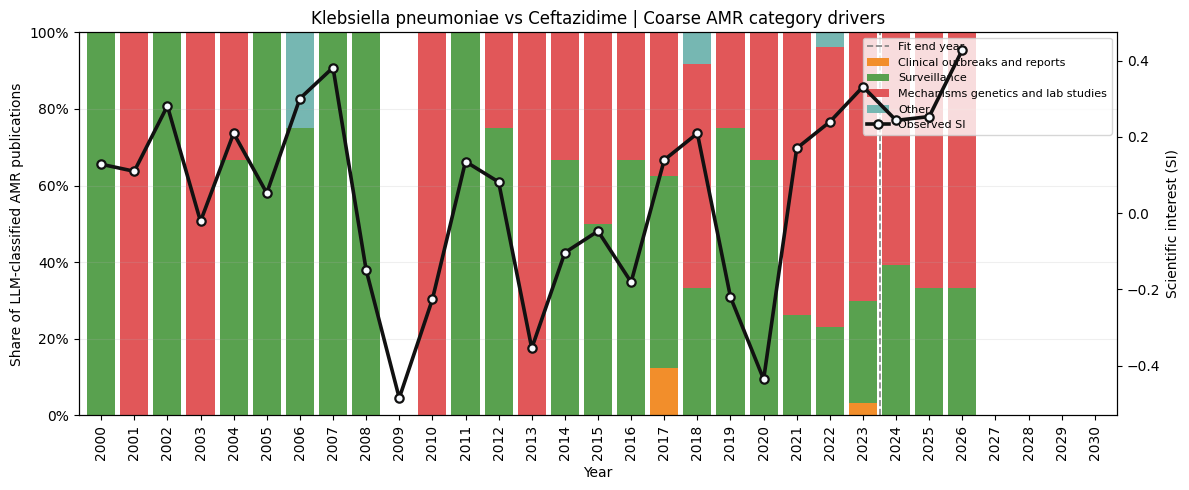

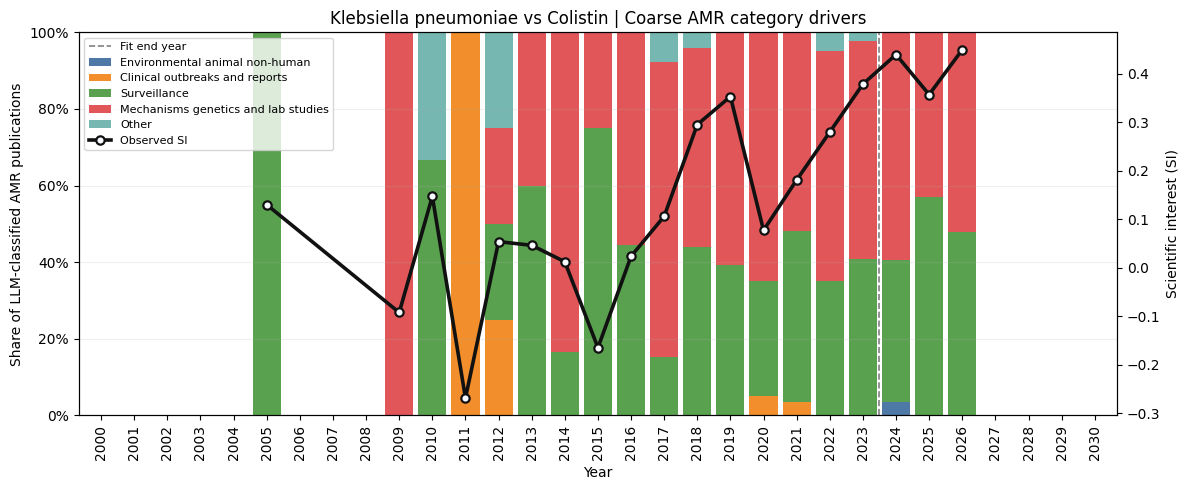

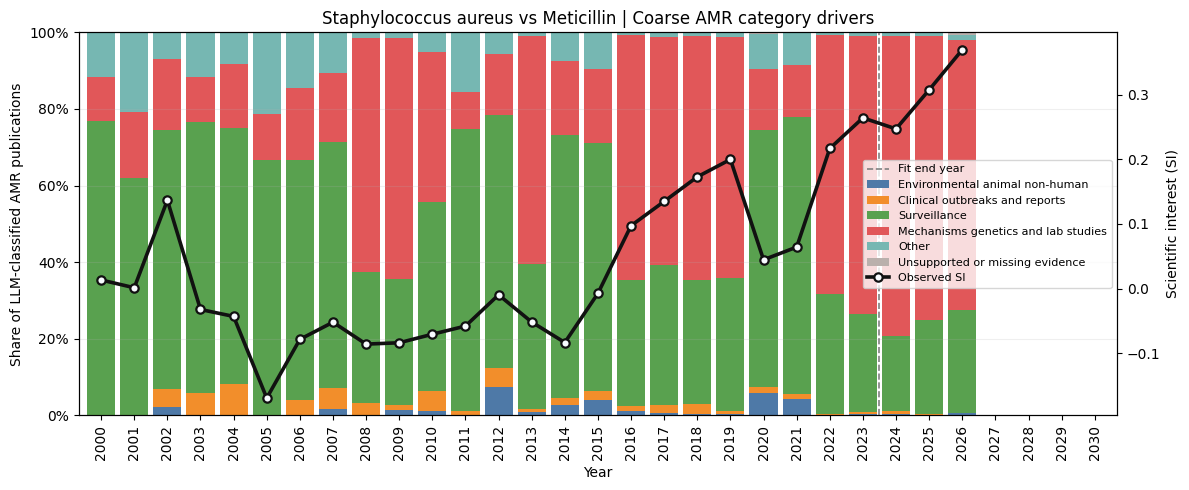

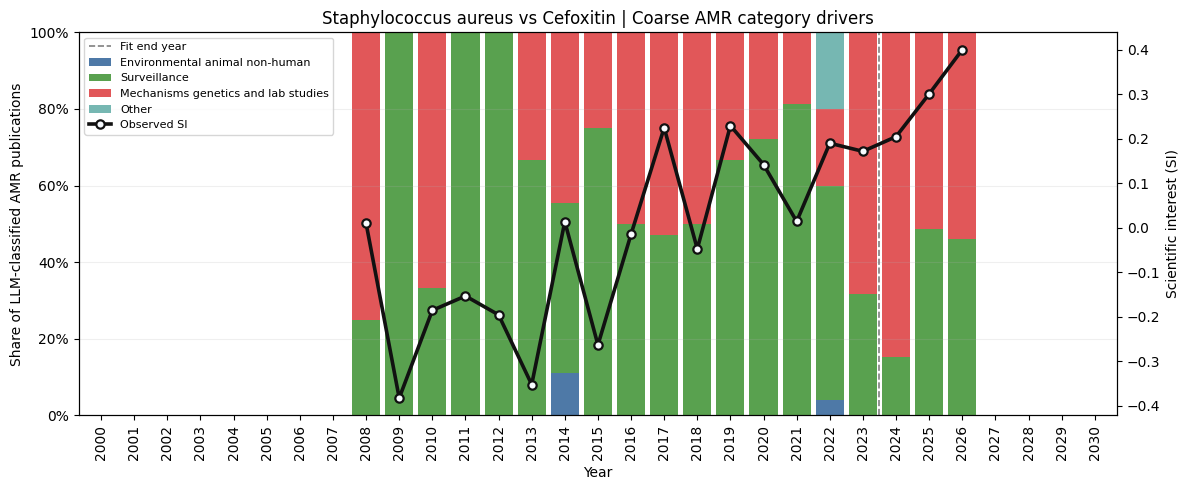

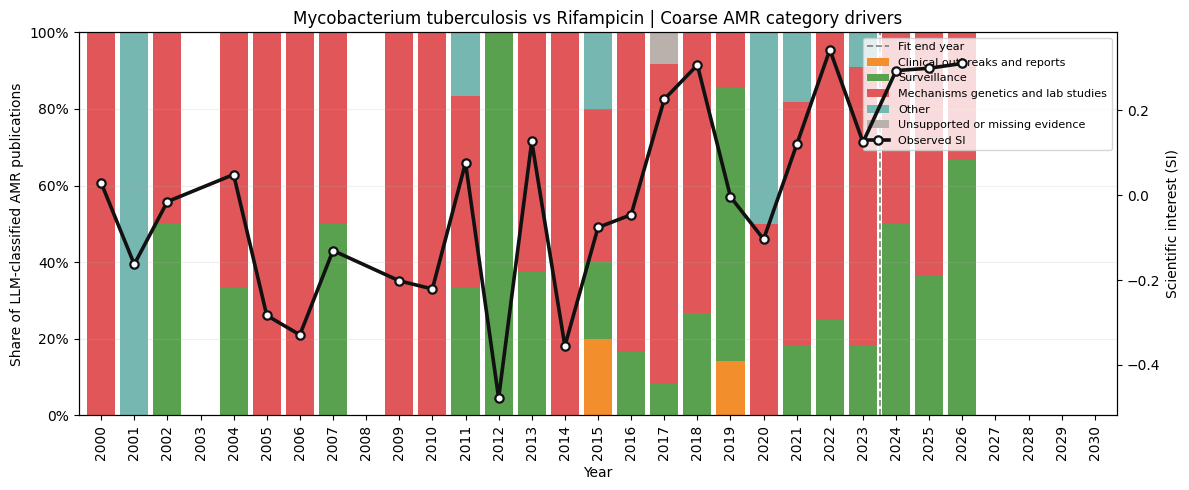

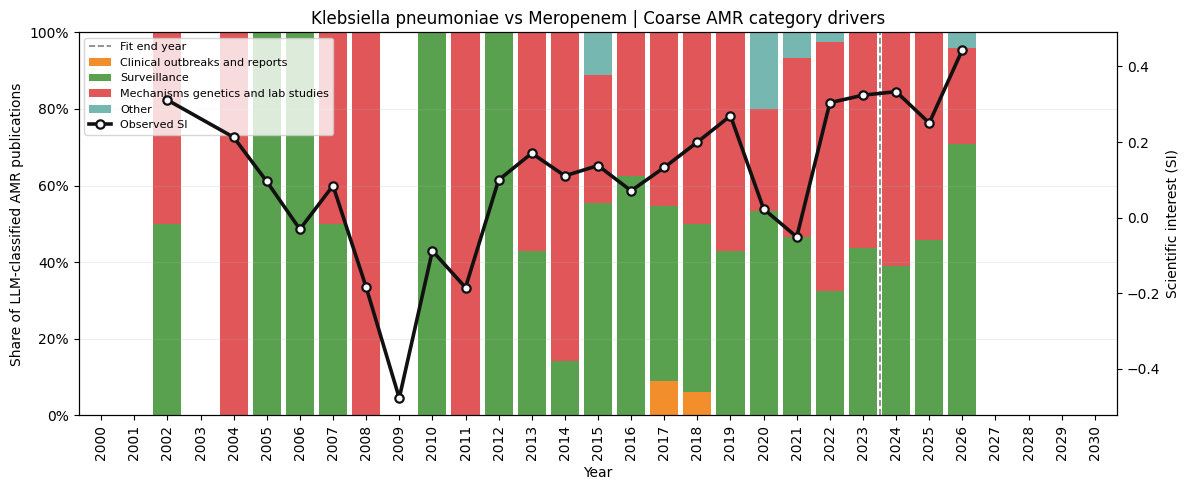

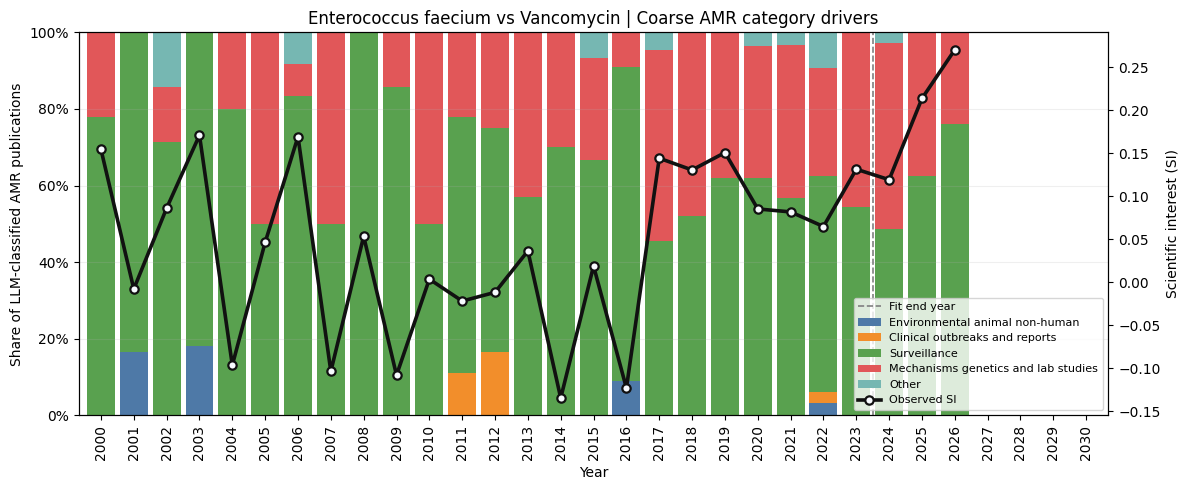

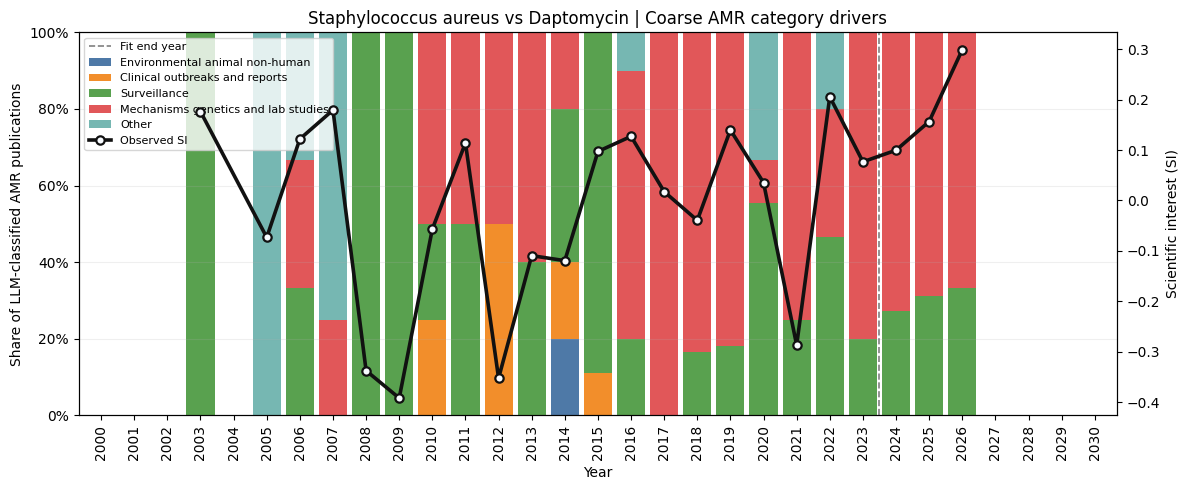

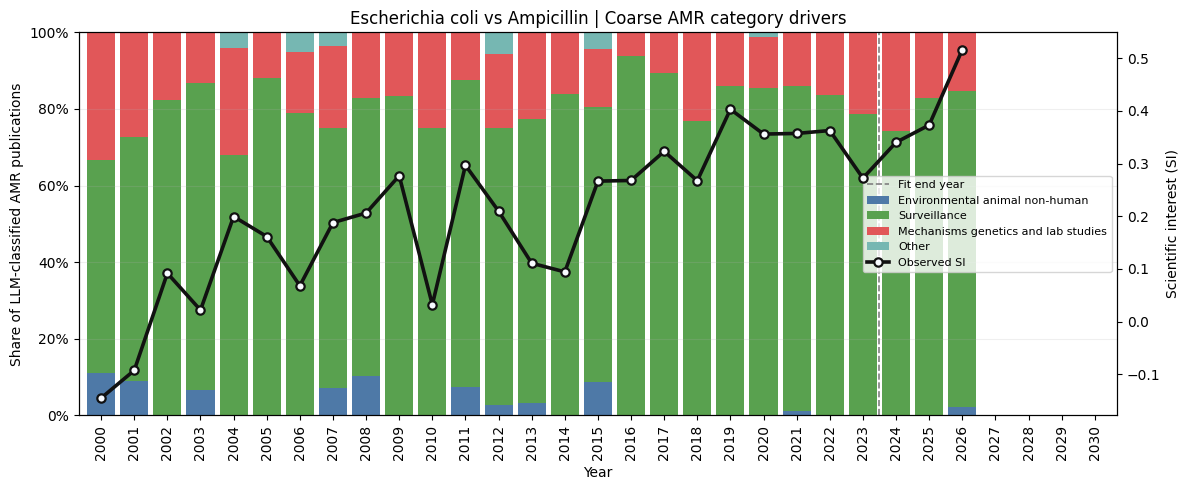

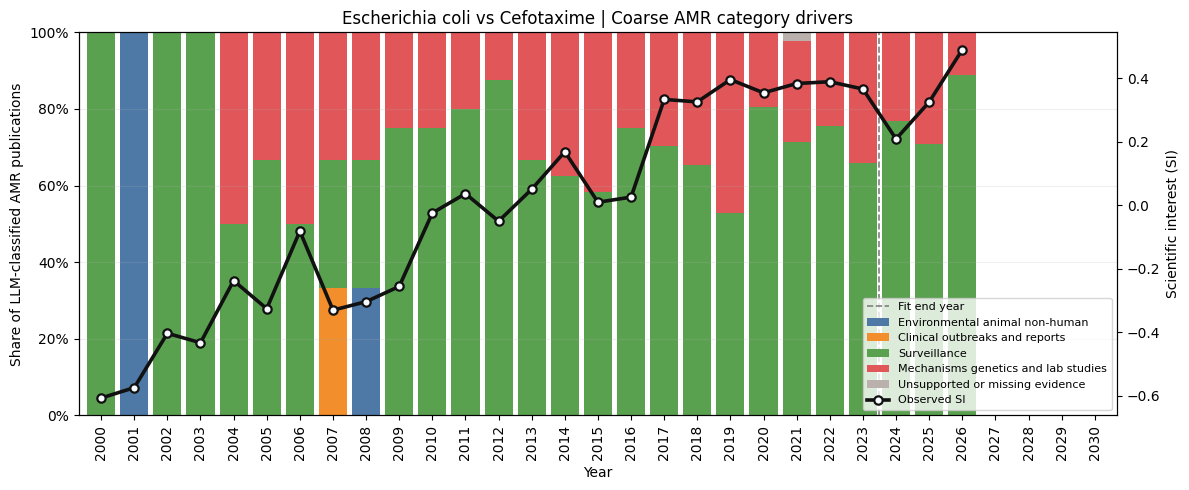

Saved 14 coarse category driver plots to /Users/f.costa/Code/Antimicrobial-Resistance/outputs/figures/interesting_yearly_si_driver_plots
Displayed 10 category driver plots inline.
Saved all-year category driver pie grid for 14 pairs to /Users/f.costa/Code/Antimicrobial-Resistance/outputs/figures/interesting_yearly_si_driver_plots/all_pairs_category_driver_pie_grid.pdf
Saved all-pair driver pie charts: 14 pairs -> /Users/f.costa/Code/Antimicrobial-Resistance/outputs/figures/interesting_yearly_si_driver_plots/all_pairs_category_driver_pie_grid.pdf


In [67]:
saved_driver_plots = save_category_driver_plots(
    category_counts_df=category_counts_df,
    si_df=si_df,
    interesting_df=interesting_df,
    output_dir=DRIVER_PLOT_DIR,
    start_year=FIT_START_YEAR,
    end_year=PLOT_END_YEAR,
    fit_end_year=FIT_END_YEAR,
    max_plots=MAX_DRIVER_PLOTS,
    figure_format=FIGURE_FORMAT,
    driver_category_level=DRIVER_CATEGORY_LEVEL,
    category_coarsening_path=DRIVER_CATEGORY_COARSENING_PATH,
    display_plots=DISPLAY_PLOTS,
    max_display_plots=MAX_DISPLAY_PLOTS,
)

driver_pie_grid_path = DRIVER_PLOT_DIR / "all_pairs_category_driver_pie_grid.pdf"
saved_driver_pie_pairs = save_category_driver_pie_grid(
    category_counts_df=category_counts_df,
    si_df=si_df,
    interesting_df=interesting_df,
    output_path=driver_pie_grid_path,
    num_columns=DRIVER_PIE_GRID_COLUMNS,
    driver_category_level=DRIVER_CATEGORY_LEVEL,
    category_coarsening_path=DRIVER_CATEGORY_COARSENING_PATH,
    verbose=True,
)
print(f"Saved all-pair driver pie charts: {saved_driver_pie_pairs:,} pairs -> {driver_pie_grid_path}")


## Plot Top Interesting Pairs


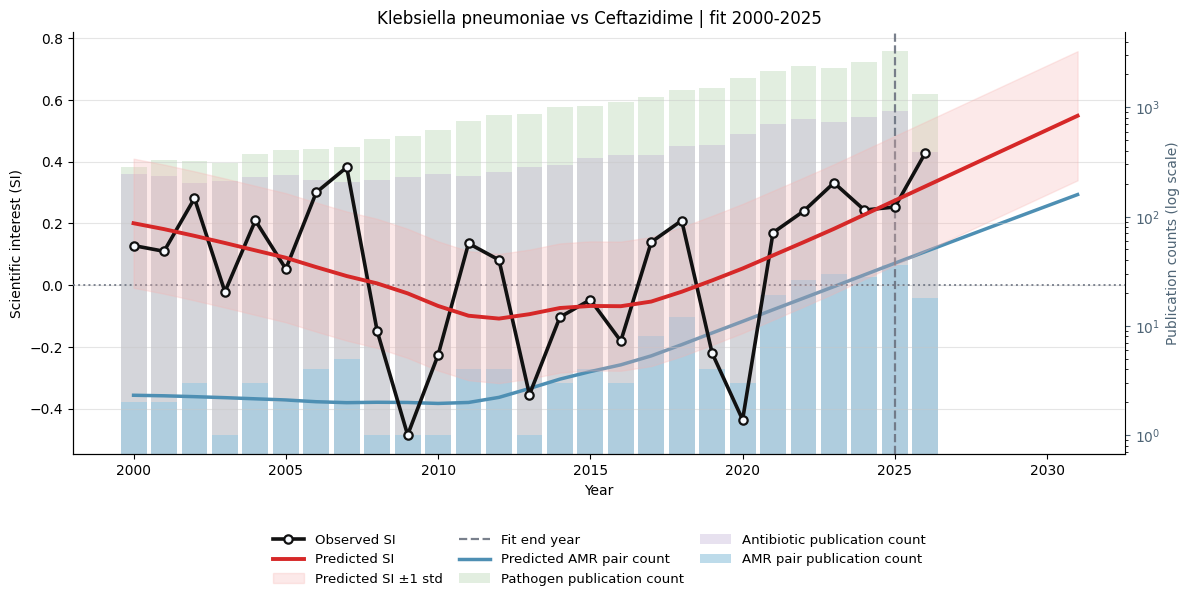

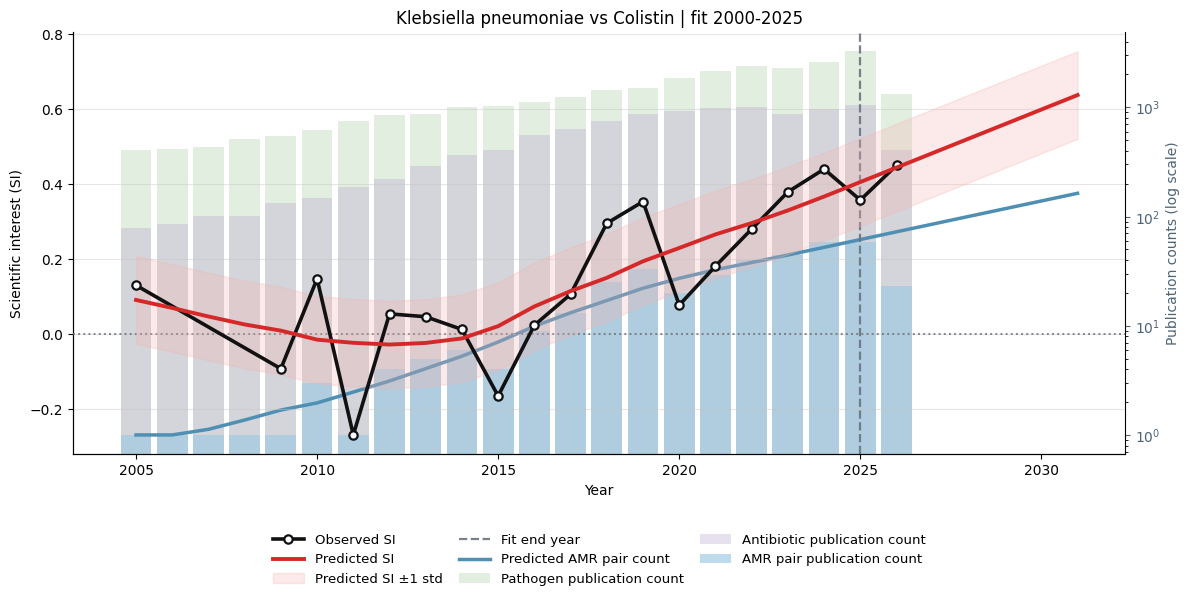

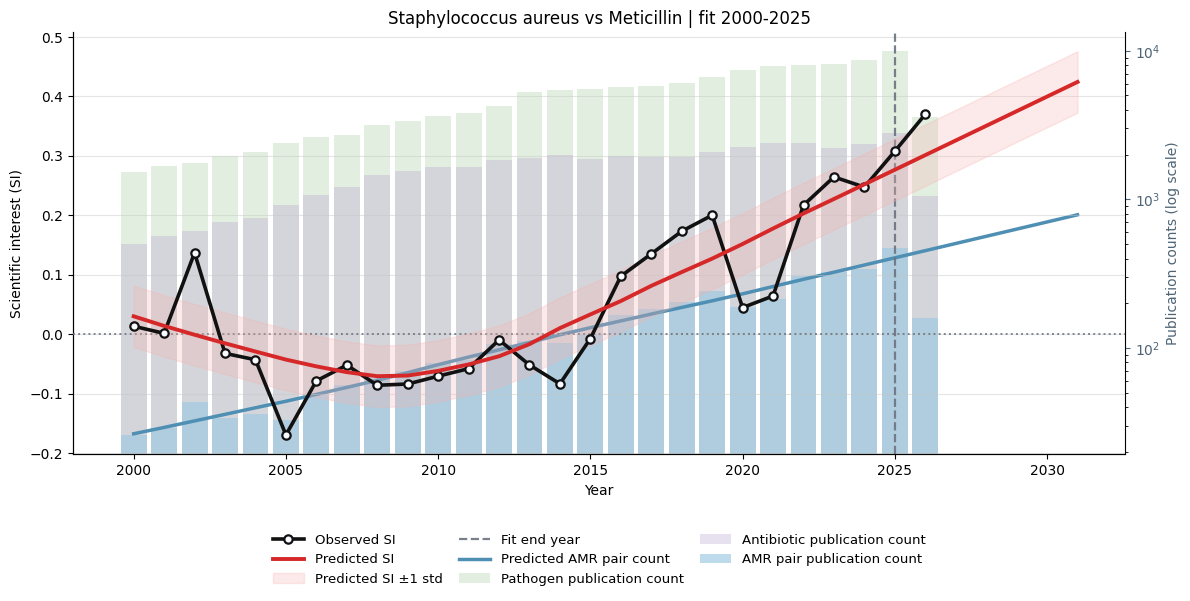

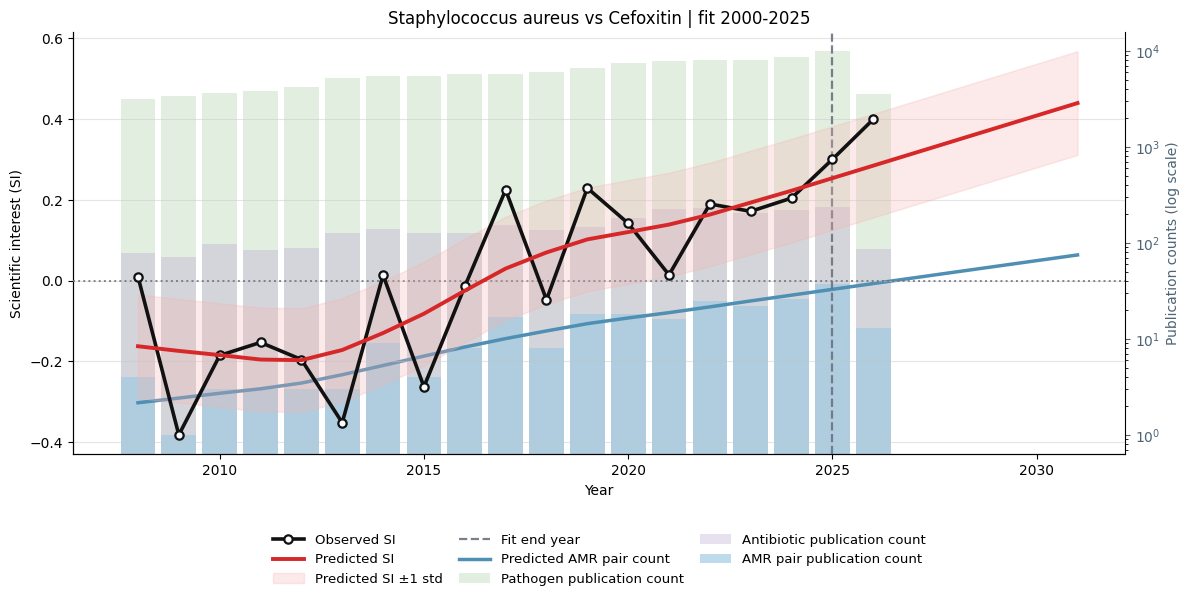

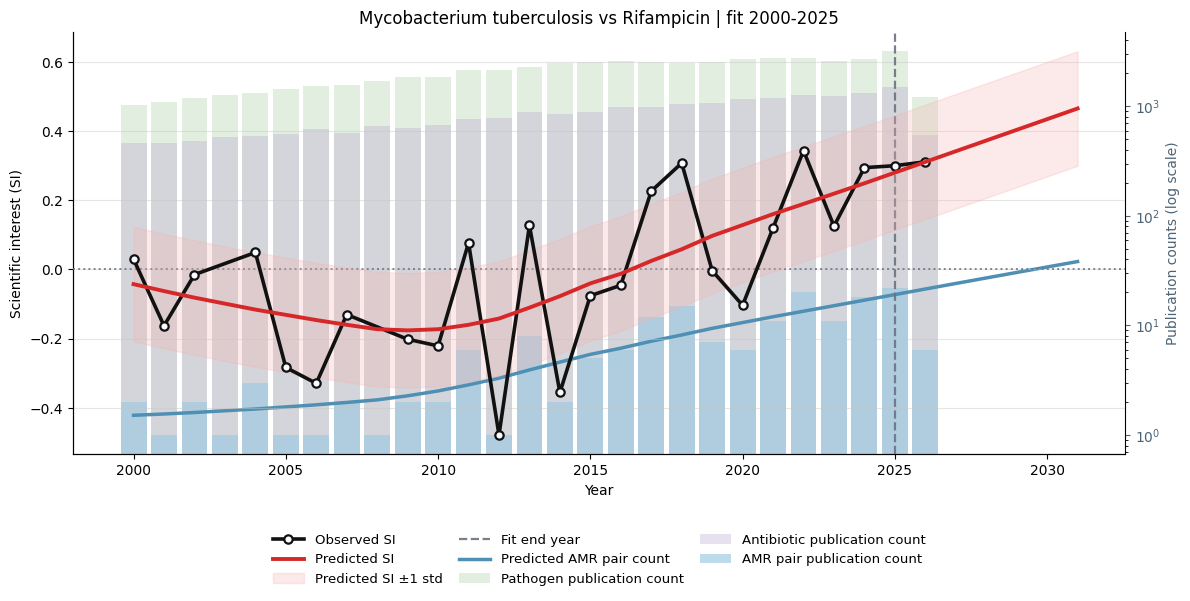

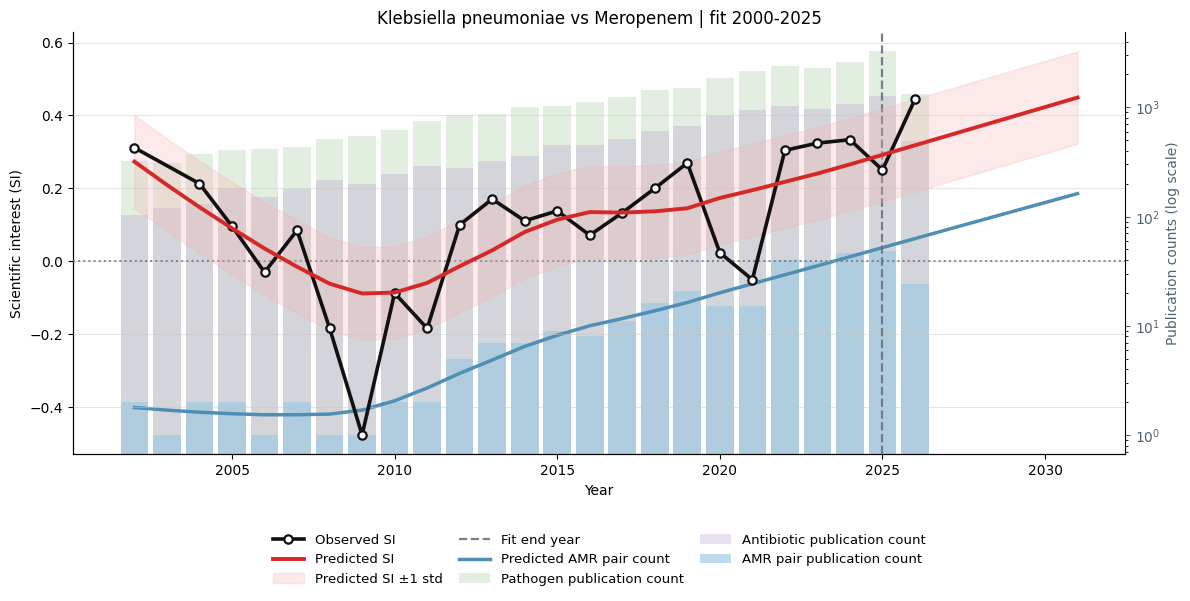

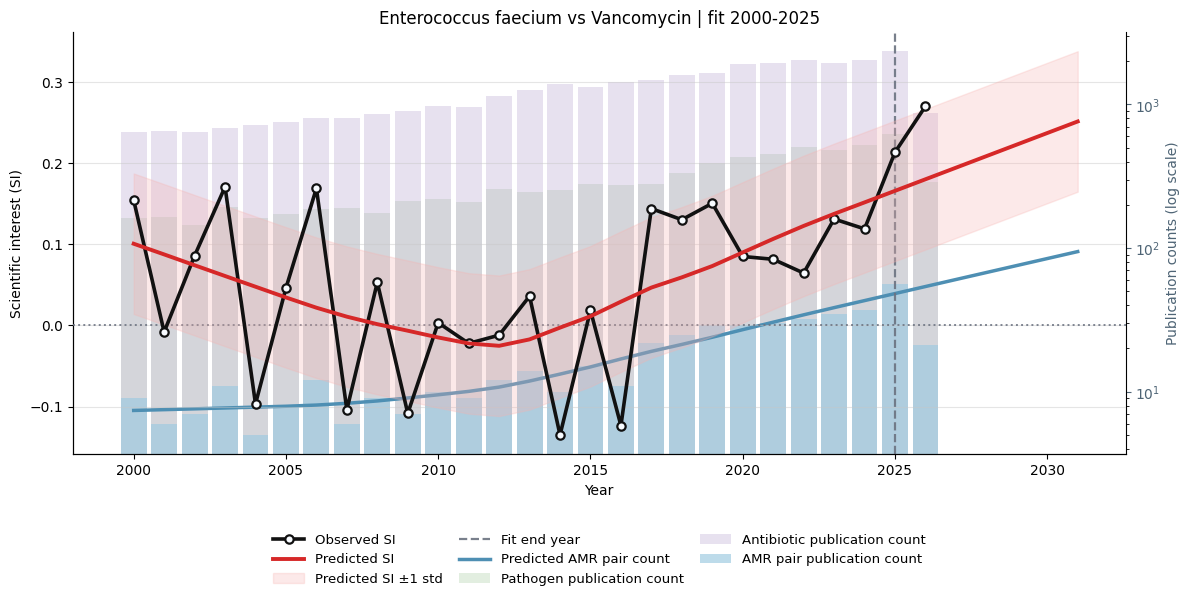

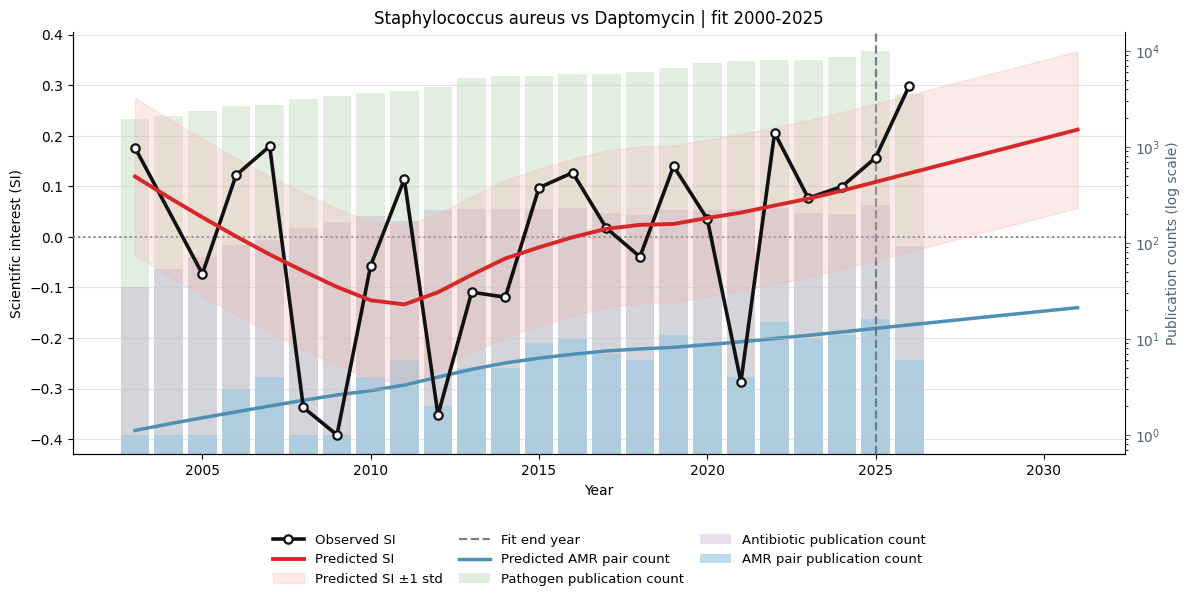

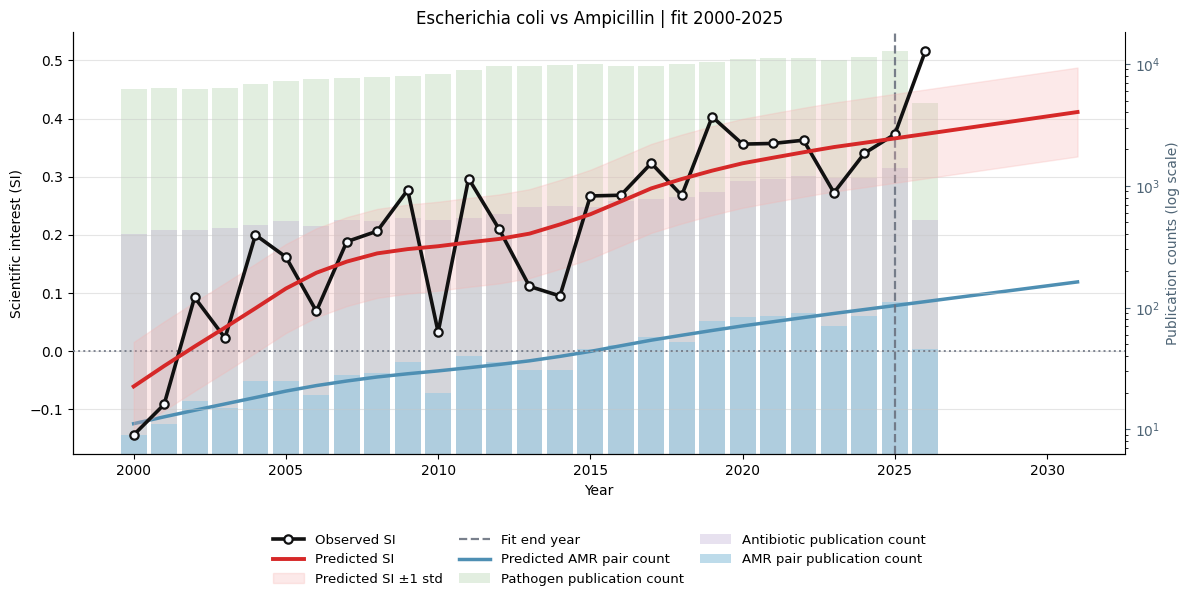

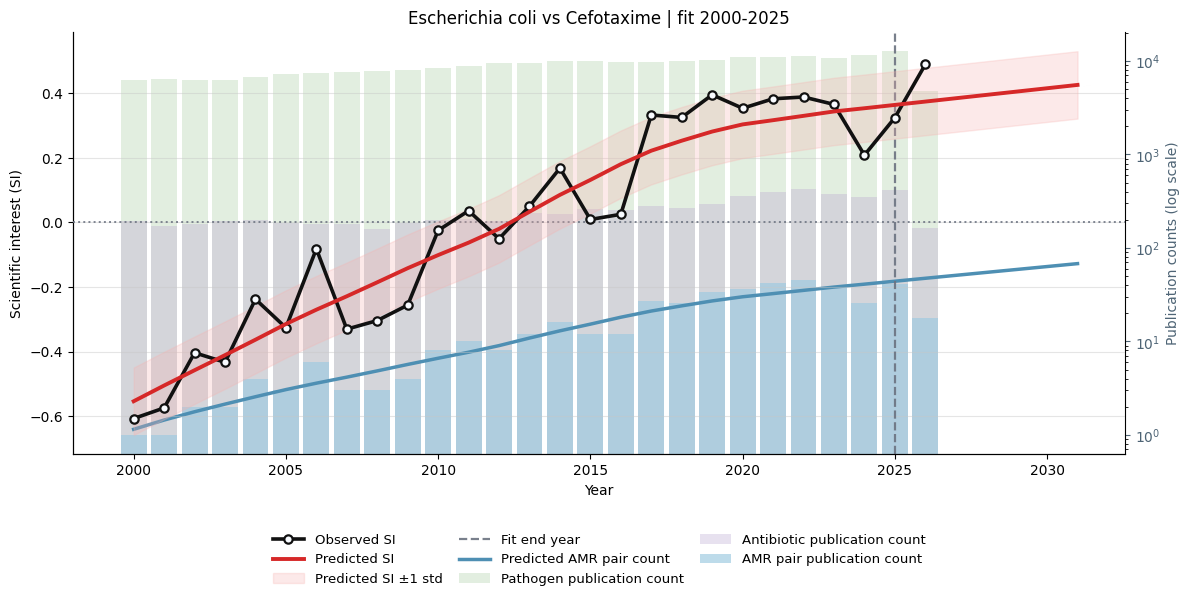

Saved 14 plots to /Users/f.costa/Code/Antimicrobial-Resistance/outputs/figures/interesting_yearly_si_plots
Displayed 10 plots inline.


In [68]:
saved_interesting_plots = save_interesting_si_plots(
    si_df=si_df,
    interesting_df=interesting_df,
    output_dir=INTERESTING_PLOT_DIR,
    fit_start_year=FIT_START_YEAR,
    fit_end_year=FIT_END_YEAR,
    num_future_years=NUM_FUTURE_YEARS,
    curve_fit_end_year=CURVE_FIT_END_YEAR,
    pathogen_background_df=pathogen_bg_df,
    antibiotic_background_df=antibiotic_bg_model_df,
    max_plots=MAX_INTERESTING_PLOTS,
    loess_frac=0.6,
    loess_degree=1,
    tail_damping_years=None,
    fill_missing_amr_counts_with_zero=FILL_MISSING_AMR_COUNTS_WITH_ZERO,
    figure_format=FIGURE_FORMAT,
    display_plots=DISPLAY_PLOTS,
    max_display_plots=MAX_DISPLAY_PLOTS,
)


## Additional SI Shape Screens


### Largest Decreasing Smoothed SI Trends


In [69]:
decreasing_smoothed_si_df = select_decreasing_smoothed_si_trends(
    rank_df,
    output_path=DECREASING_SI_OUTPUT_PATH,
)

select_existing_columns(
    decreasing_smoothed_si_df,
    DEFAULT_DECREASING_SI_SUMMARY_COLUMNS,
    head=10,
)


Saved decreasing smoothed SI table: 58 rows -> /Users/f.costa/Code/Antimicrobial-Resistance/outputs/parquets/decreasing_smoothed_si_trends.parquet


,pathogen,antibiotic,reference_year,future_year,current_predicted_SI,future_predicted_SI,si_change,current_predicted_count,future_predicted_count,si_loess_residual_variance_mean,post_fit_si_abs_pct_error_mean
0,Streptococcus pneumoniae,Chloramphenicol,2025,2030,-0.655791,-0.961579,-0.305788,0.365798,0.000000,0.042272,45.879949
1,Streptococcus pneumoniae,Sulfamethoxazole,2025,2030,-0.615870,-0.894811,-0.278942,1.210245,0.586423,0.066531,16.434850
2,Enterococcus faecalis,Erythromycin,2025,2030,-0.243383,-0.493843,-0.250460,3.714932,2.543967,0.033308,74.412575
3,Enterococcus faecium,Ampicillin,2025,2030,-0.405334,-0.648996,-0.243662,4.788043,4.111796,0.011910,39.856654
4,Staphylococcus aureus,Sulfamethoxazole/trimethoprim,2025,2030,-0.290201,-0.486789,-0.196588,6.825890,6.358845,0.031885,79.027772
5,Streptococcus pneumoniae,Sulfamethoxazole/trimethoprim,2025,2030,-0.459899,-0.649397,-0.189498,1.713520,1.276980,0.066532,63.856641
6,Salmonella enterica,Streptomycin,2025,2030,-0.137285,-0.317369,-0.180084,7.582108,5.394167,0.022156,64.144396
7,Salmonella enterica,Tetracycline,2025,2030,-0.161916,-0.341321,-0.179406,16.019150,15.588596,0.013940,53.850738
8,Neisseria gonorrhoeae,Tetracycline,2025,2030,-0.394895,-0.565588,-0.170693,8.423131,8.642248,0.025884,32.441584
9,Neisseria gonorrhoeae,Azithromycin,2025,2030,0.007116,-0.158476,-0.165592,21.566328,19.655034,0.014809,13631.727599


### Most Convex and Concave Smoothed SI Curves


In [70]:
smoothed_si_shape_df = summarize_smoothed_si_shapes(
    rank_df,
    si_df,
    fit_start_year=FIT_START_YEAR,
    curve_fit_end_year=CURVE_FIT_END_YEAR,
    num_future_years=NUM_FUTURE_YEARS,
    loess_frac=0.6,
    loess_degree=1,
    tail_damping_years=None,
)

most_convex_smoothed_si_df, most_concave_smoothed_si_df = select_smoothed_si_shape_cases(
    smoothed_si_shape_df,
    top_n=10,
    convex_output_path=CONVEX_SI_OUTPUT_PATH,
    concave_output_path=CONCAVE_SI_OUTPUT_PATH,
)

print("Most convex U-shaped smoothed SI curves")
select_existing_columns(
    most_convex_smoothed_si_df,
    DEFAULT_SMOOTHED_SI_SHAPE_SUMMARY_COLUMNS,
    head=10,
)

print("Most concave inverted-U smoothed SI curves")
select_existing_columns(
    most_concave_smoothed_si_df,
    DEFAULT_SMOOTHED_SI_SHAPE_SUMMARY_COLUMNS,
    head=10,
)


Saved convex U-shaped smoothed SI table: 10 rows -> /Users/f.costa/Code/Antimicrobial-Resistance/outputs/parquets/convex_u_shaped_smoothed_si_trends.parquet
Saved concave inverted-U smoothed SI table: 10 rows -> /Users/f.costa/Code/Antimicrobial-Resistance/outputs/parquets/concave_inverted_u_smoothed_si_trends.parquet
Most convex U-shaped smoothed SI curves
Most concave inverted-U smoothed SI curves


,pathogen,antibiotic,shape_start_year,shape_midpoint_year,curve_fit_end_year,shape_end_year,start_predicted_SI,midpoint_predicted_SI,end_predicted_SI,endpoint_balance_abs_diff,convex_u_score,concave_cap_score,si_quadratic_coef,si_quadratic_r2,si_change,si_loess_residual_variance_mean
0,Neisseria gonorrhoeae,Azithromycin,2001,2016,2025,2030,-0.338366,0.172361,-0.158476,0.179890,-0.420782,0.420782,-0.001854,0.879901,-0.165592,0.014809
1,Enterococcus faecalis,Erythromycin,2000,2015,2025,2030,-0.079780,0.088283,-0.493843,0.414063,-0.375094,0.375094,-0.001670,0.981889,-0.250460,0.033308
2,Helicobacter pylori,Levofloxacin,2005,2018,2025,2030,-0.542577,0.170027,0.190922,0.733500,-0.345855,0.345855,-0.002148,0.995818,-0.011655,0.011898
3,Escherichia coli,Tetracycline,2000,2015,2025,2030,-0.071474,0.254126,-0.054405,0.017069,-0.317065,0.317065,-0.001500,0.964113,-0.127533,0.014140
4,Salmonella enterica,Tetracycline,2000,2015,2025,2030,-0.023563,0.133769,-0.341321,0.317758,-0.316211,0.316211,-0.001471,0.983299,-0.179406,0.013940
5,Staphylococcus aureus,Tetracycline,2000,2015,2025,2030,-0.142713,0.224902,-0.021810,0.120903,-0.307163,0.307163,-0.001325,0.854108,-0.097044,0.019417
6,Neisseria gonorrhoeae,Ceftriaxone,2000,2015,2025,2030,-0.079479,0.325125,0.140265,0.219744,-0.294732,0.294732,-0.001284,0.942820,-0.093580,0.009480
7,Staphylococcus aureus,Rifampicin,2000,2015,2025,2030,-0.252759,0.040798,-0.250956,0.001803,-0.292656,0.292656,-0.001433,0.957995,-0.123539,0.024291
8,Salmonella enterica,Streptomycin,2000,2015,2025,2030,0.020637,0.134166,-0.317369,0.338006,-0.282532,0.282532,-0.001355,0.985752,-0.180084,0.022156
9,Enterococcus faecium,Ampicillin,2001,2016,2025,2030,0.053275,-0.043940,-0.648996,0.702271,-0.253921,0.253921,-0.001303,0.998219,-0.243662,0.011910


### Plots for Additional SI Shape Screens


In [71]:
# SHAPE_SCREEN_PLOT_COUNT is loaded from PIPELINE_CONFIG in the main config cell.


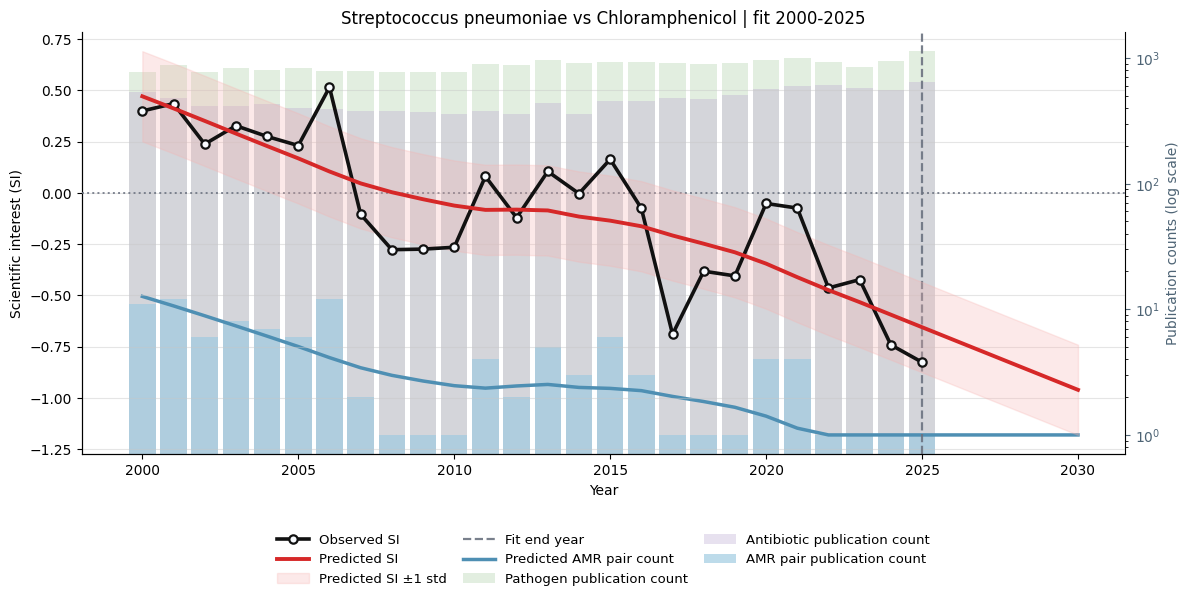

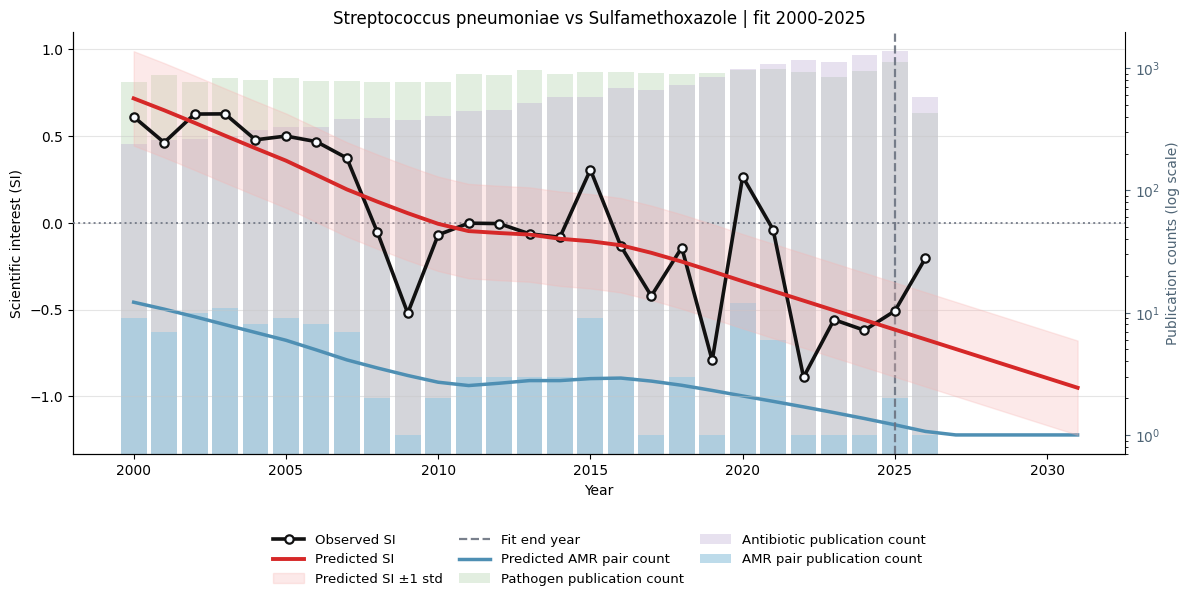

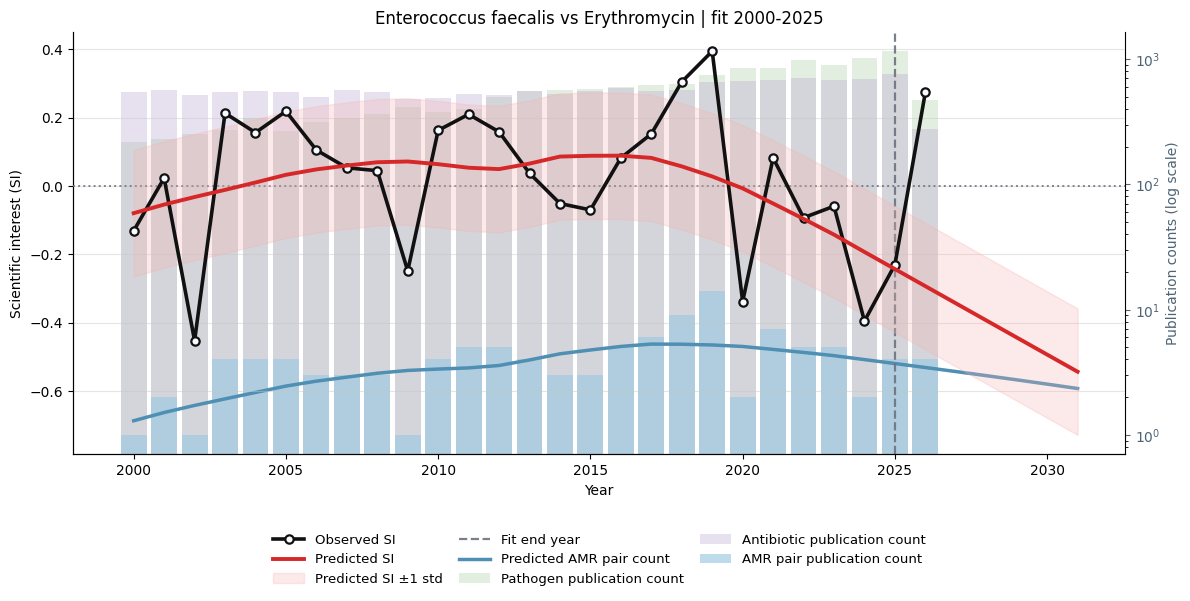

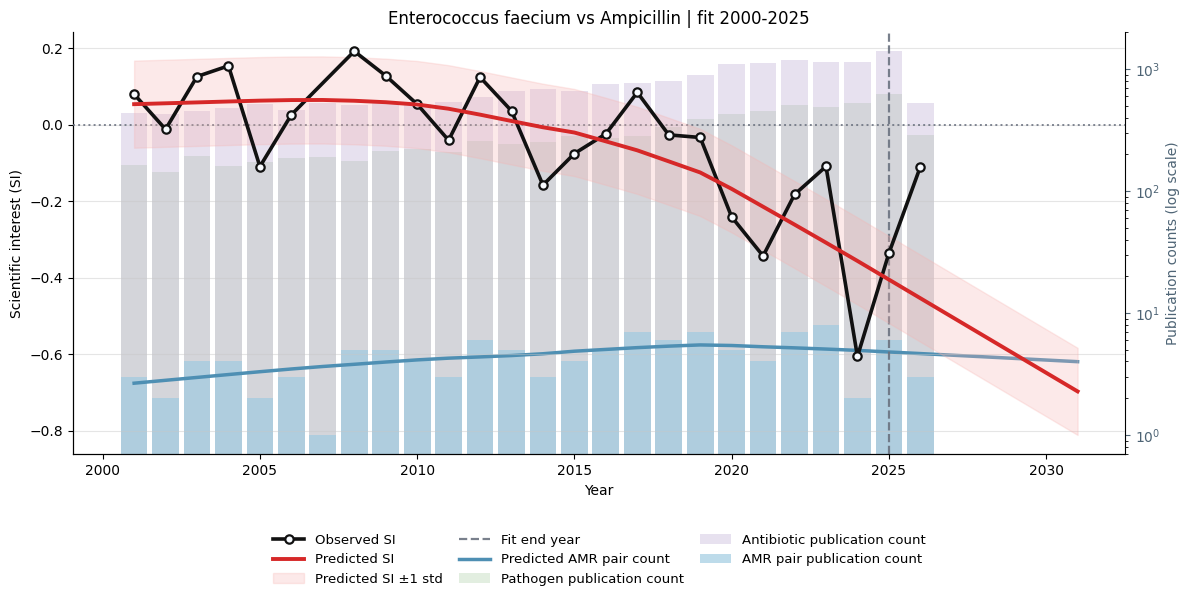

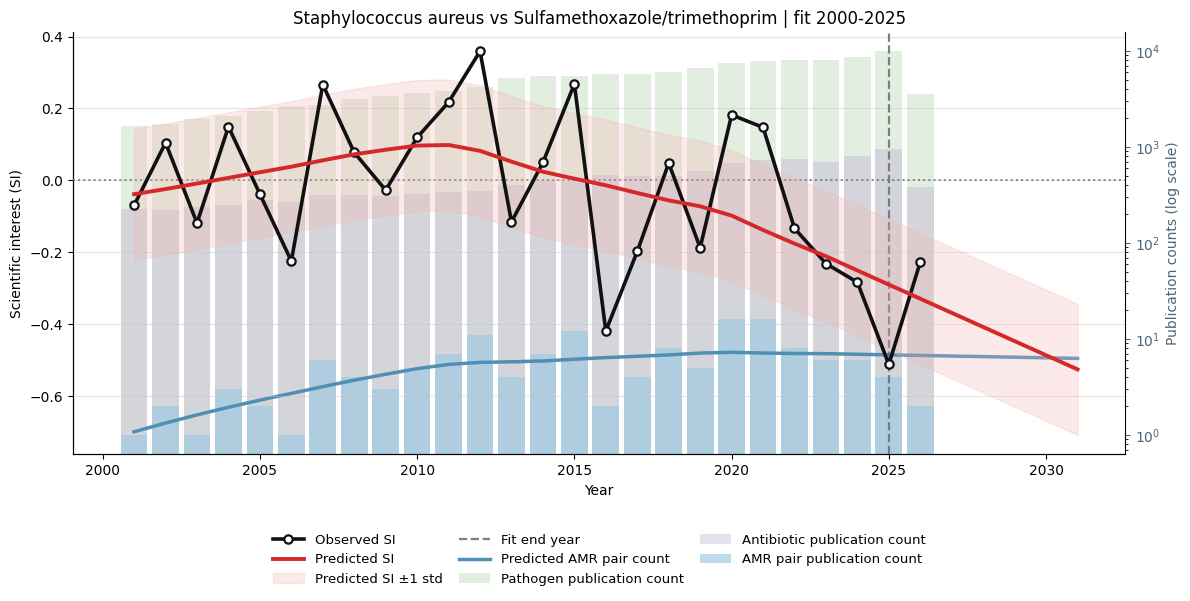

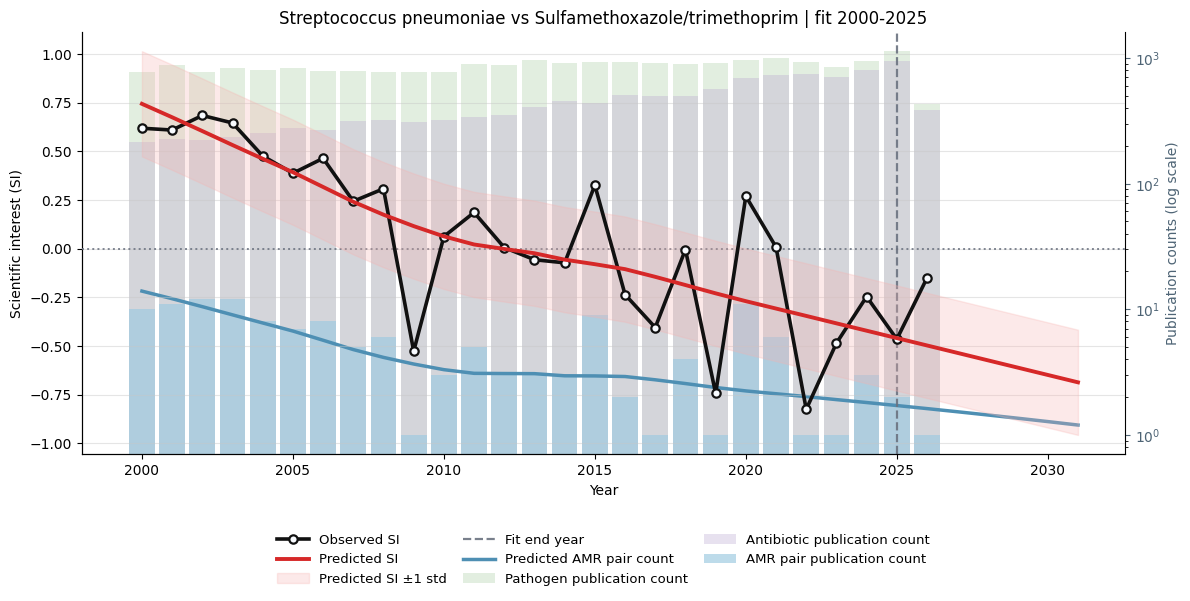

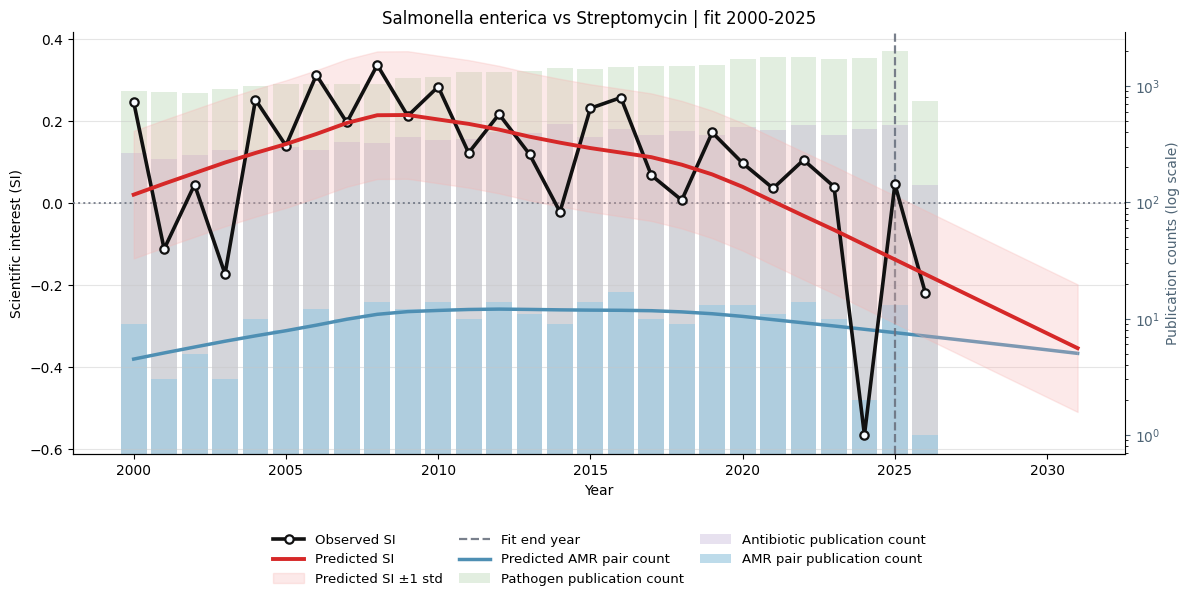

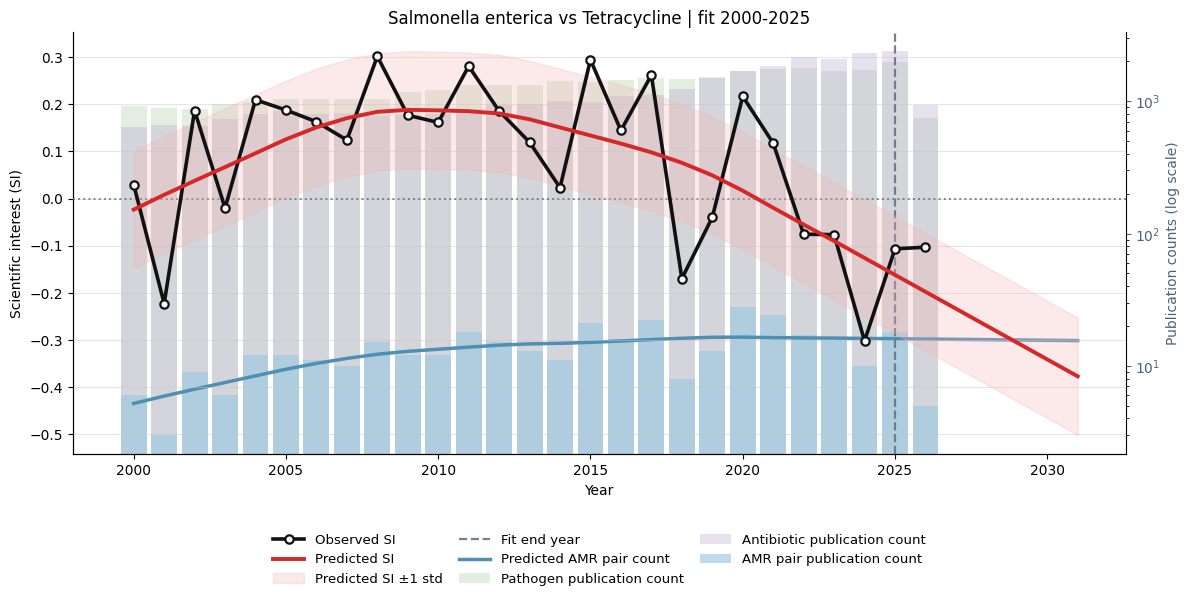

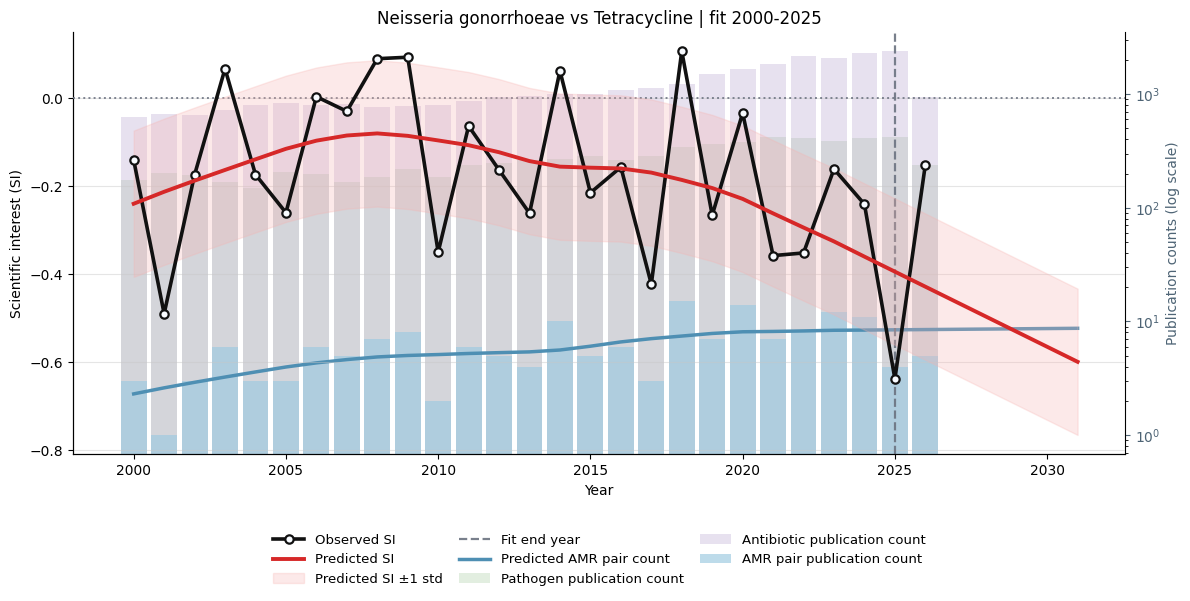

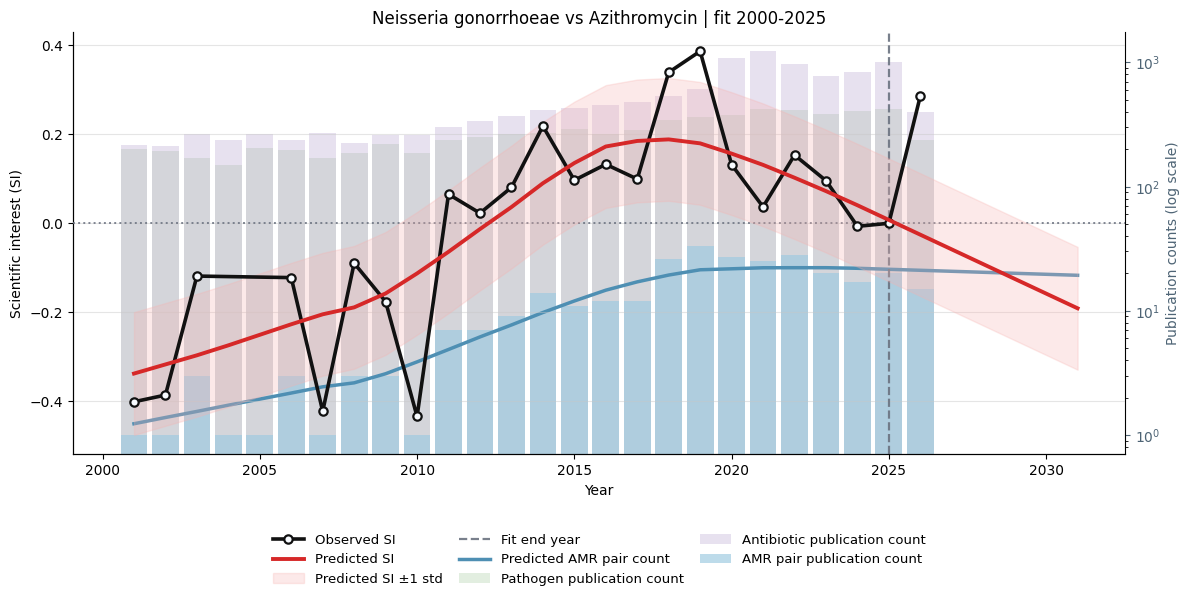

Saved 10 smoothed SI screen plots to /Users/f.costa/Code/Antimicrobial-Resistance/outputs/figures/decreasing_smoothed_si_plots


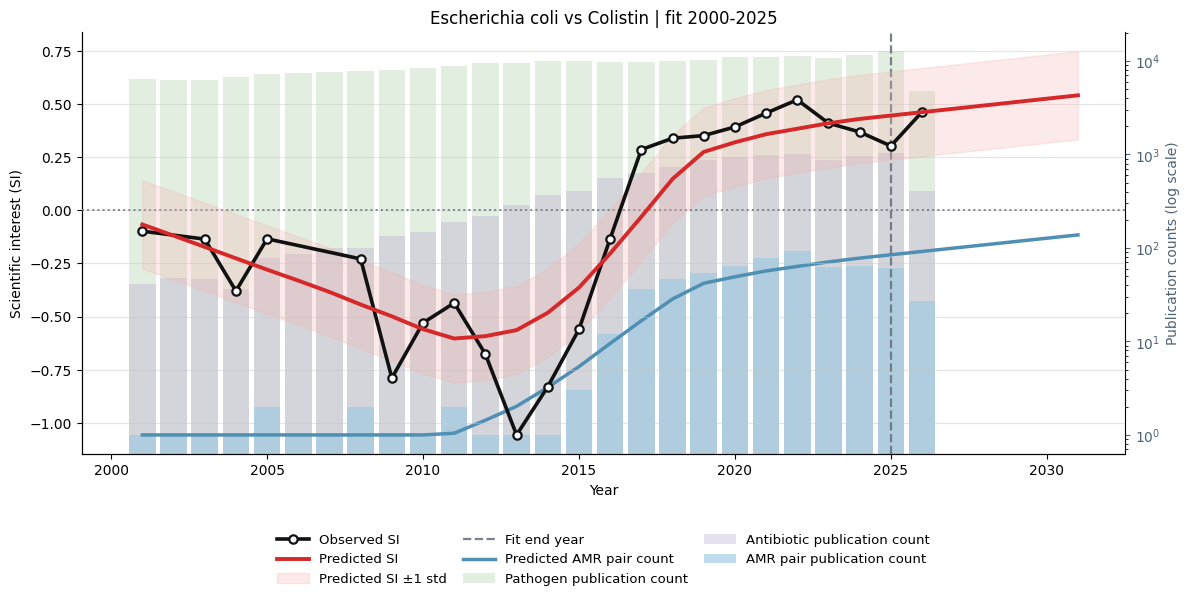

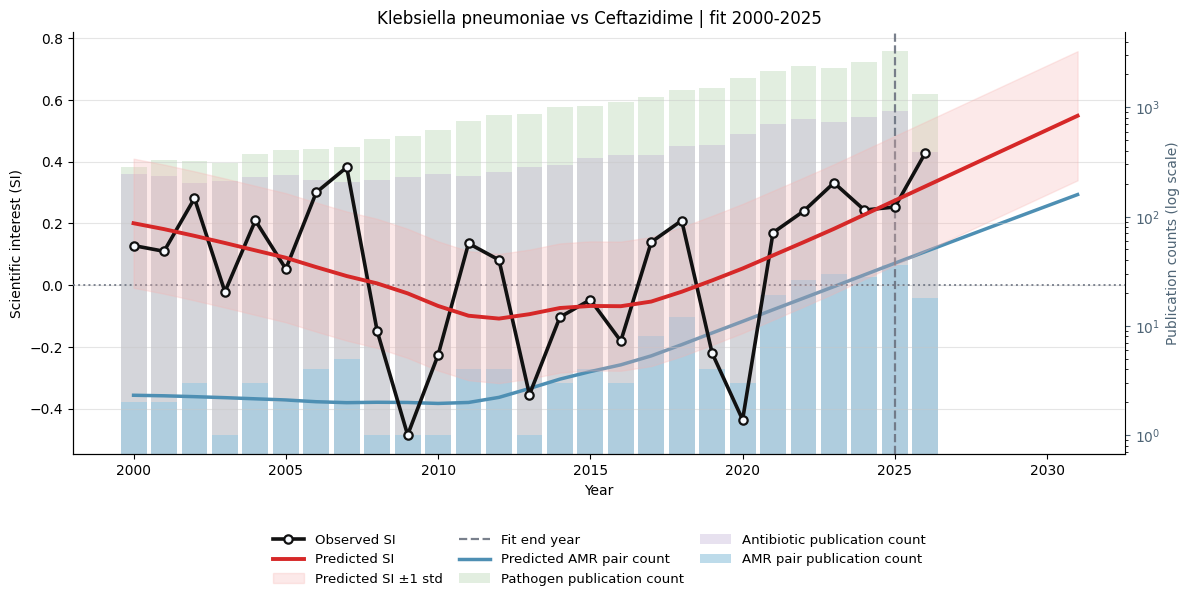

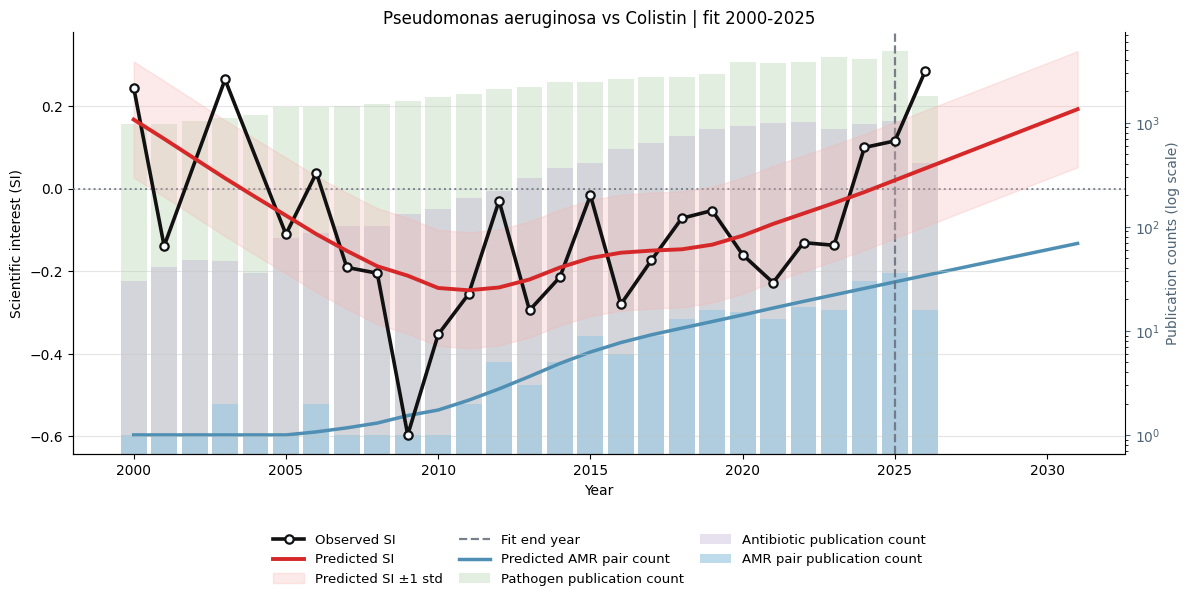

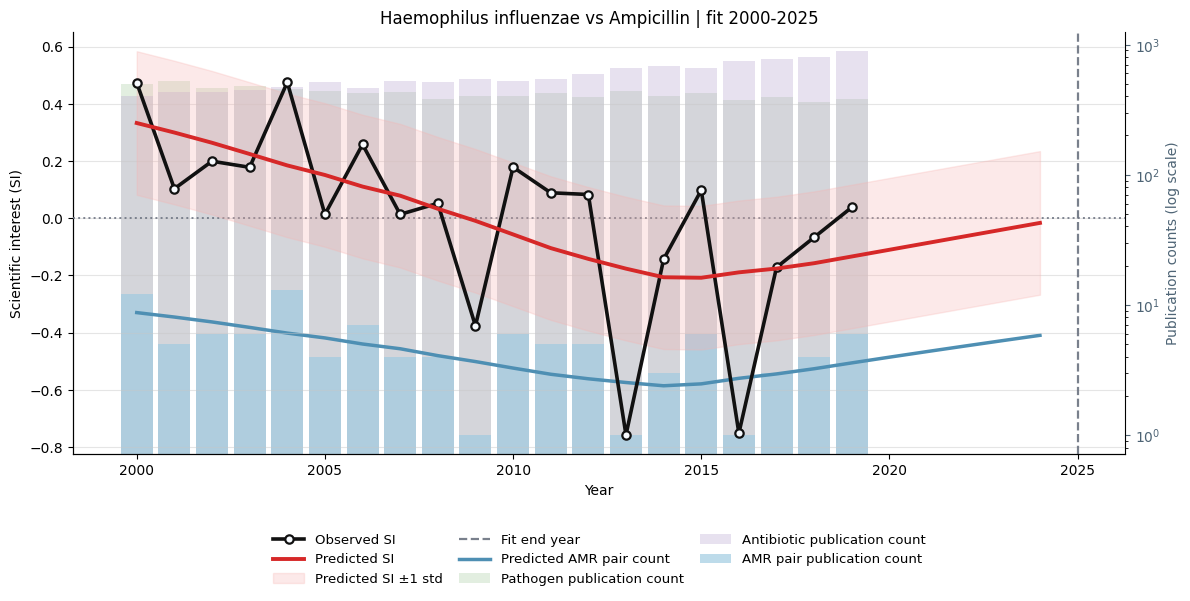

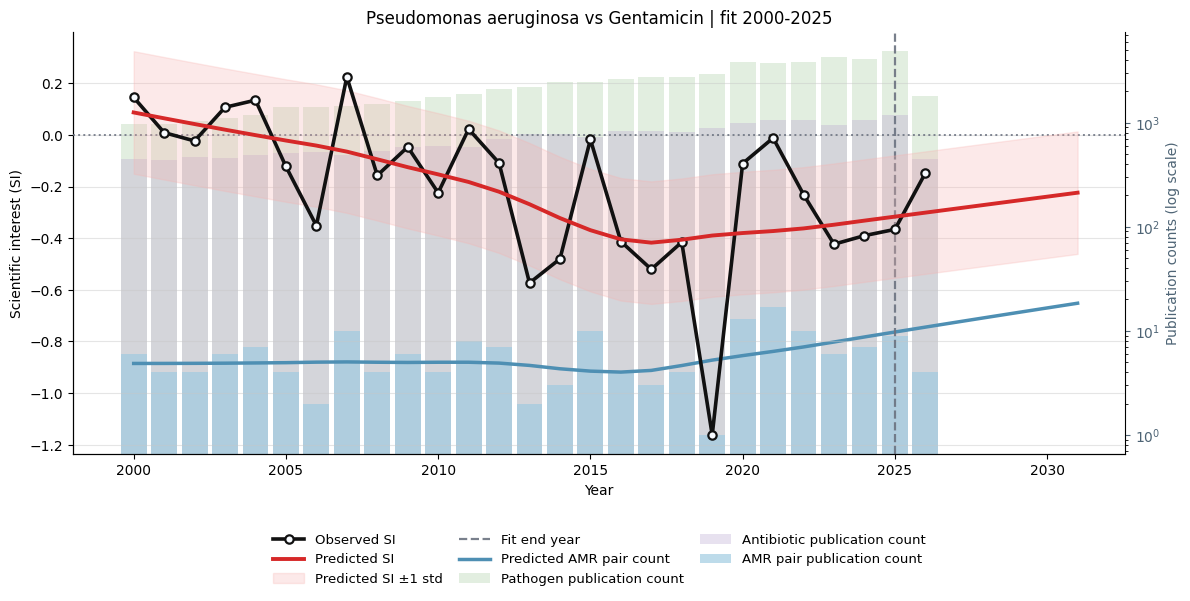

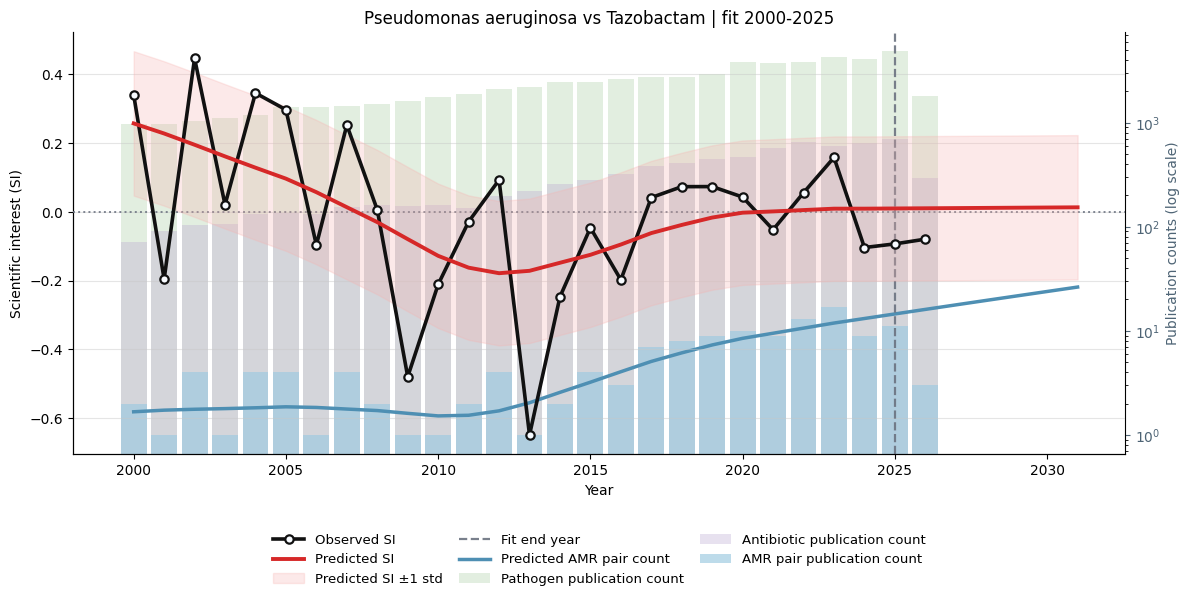

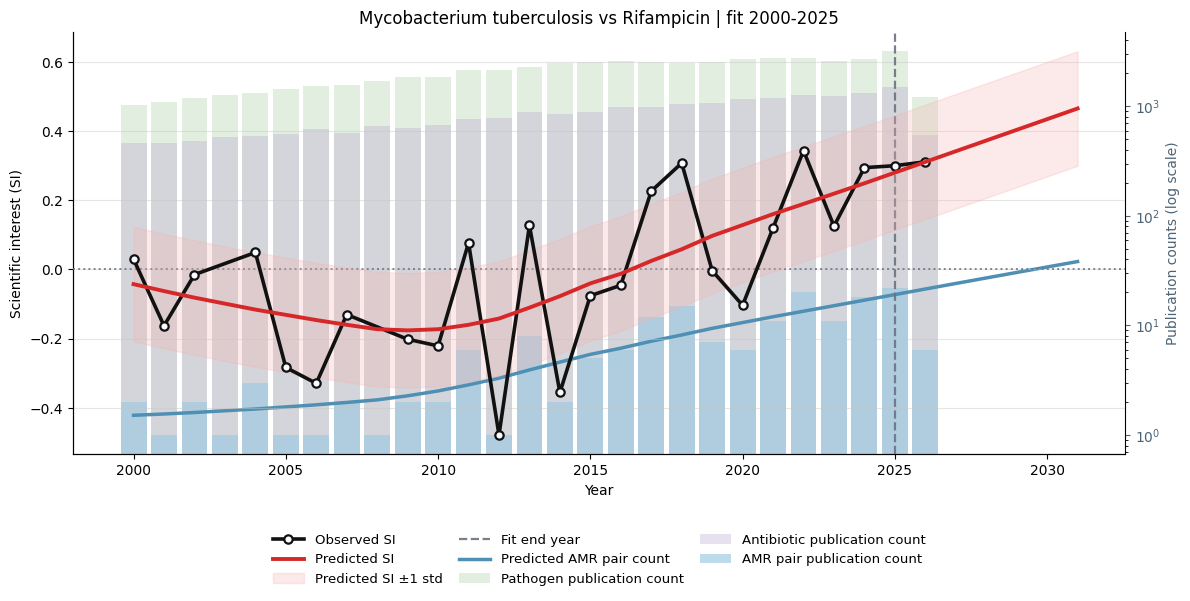

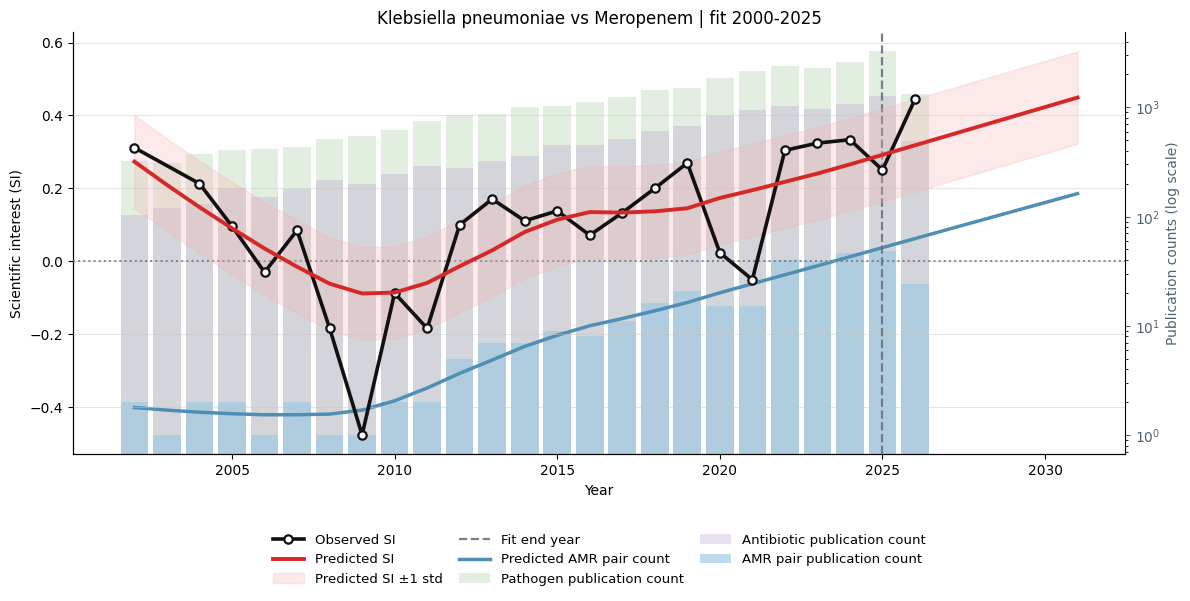

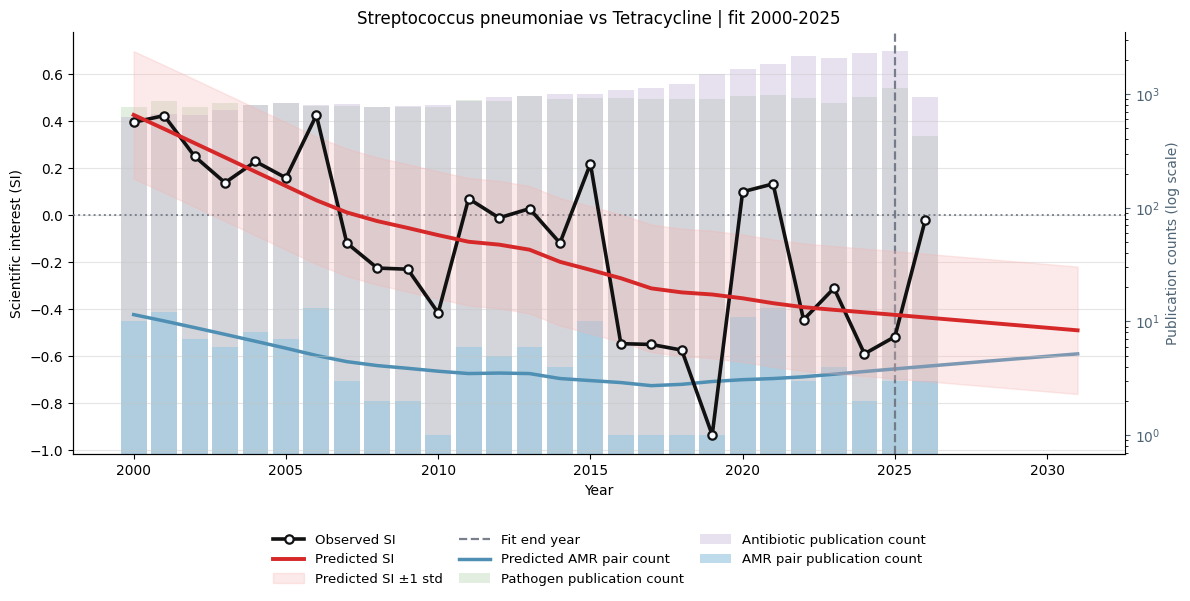

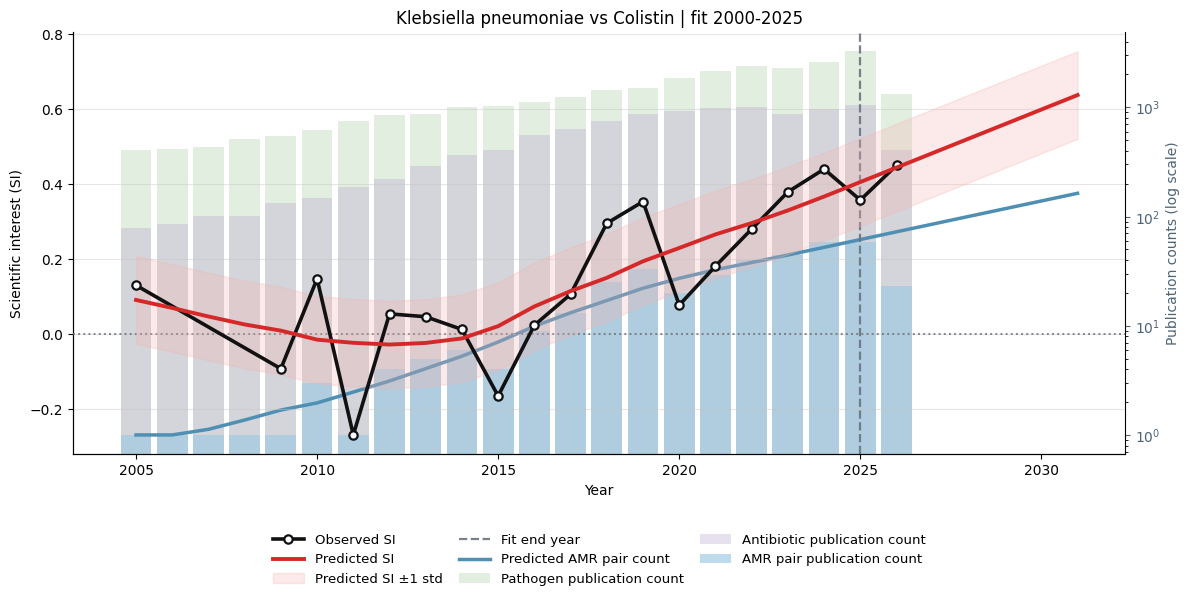

Saved 10 smoothed SI screen plots to /Users/f.costa/Code/Antimicrobial-Resistance/outputs/figures/convex_u_shaped_smoothed_si_plots


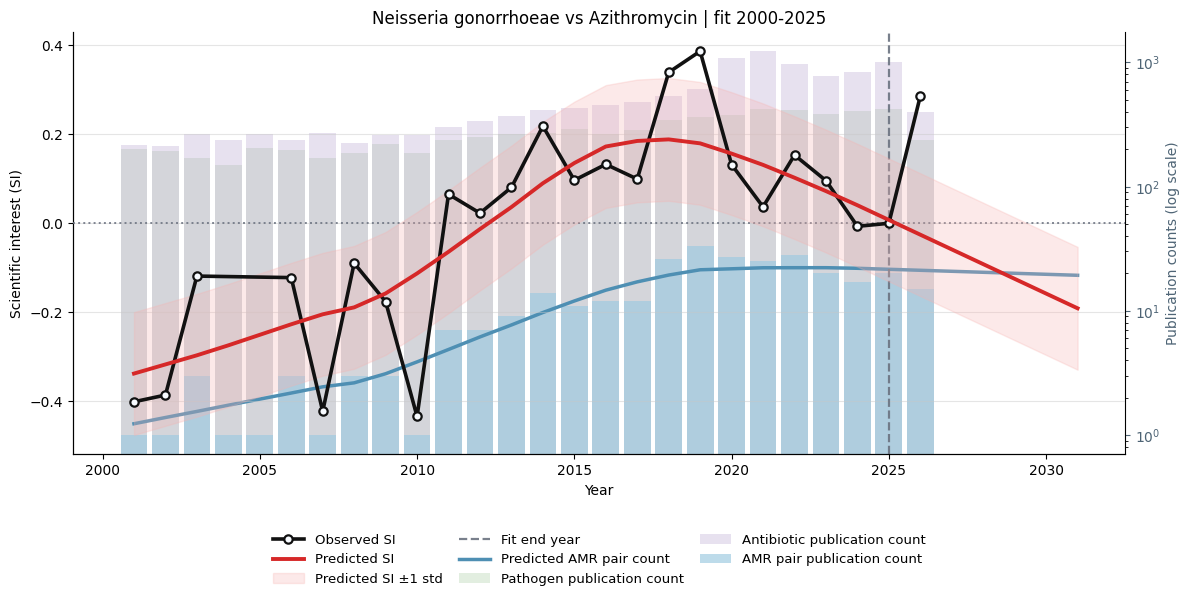

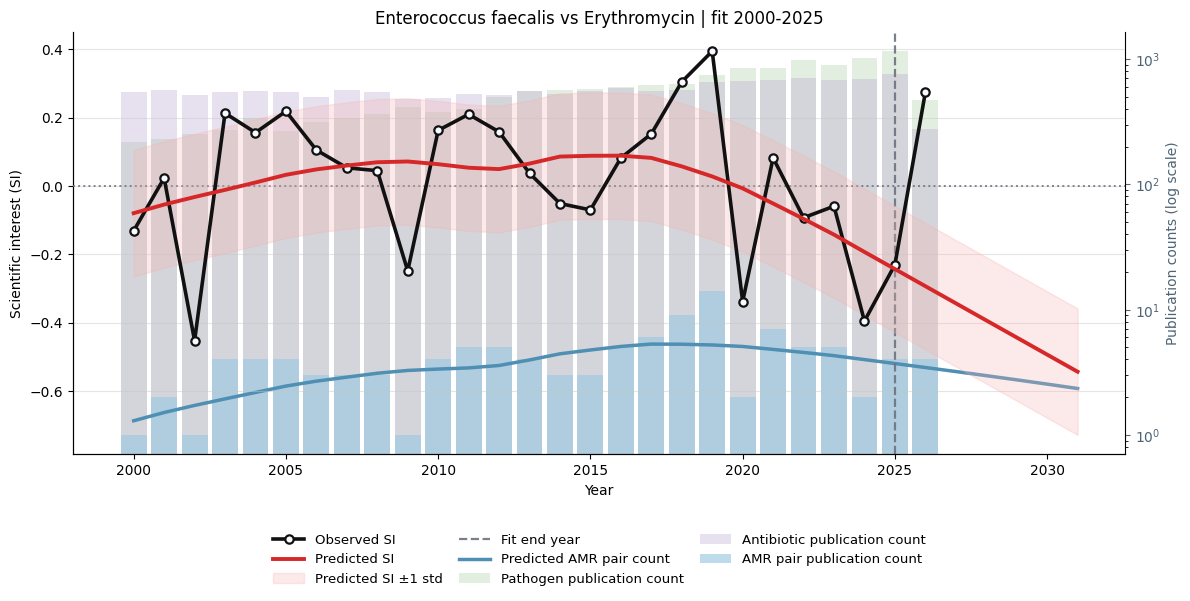

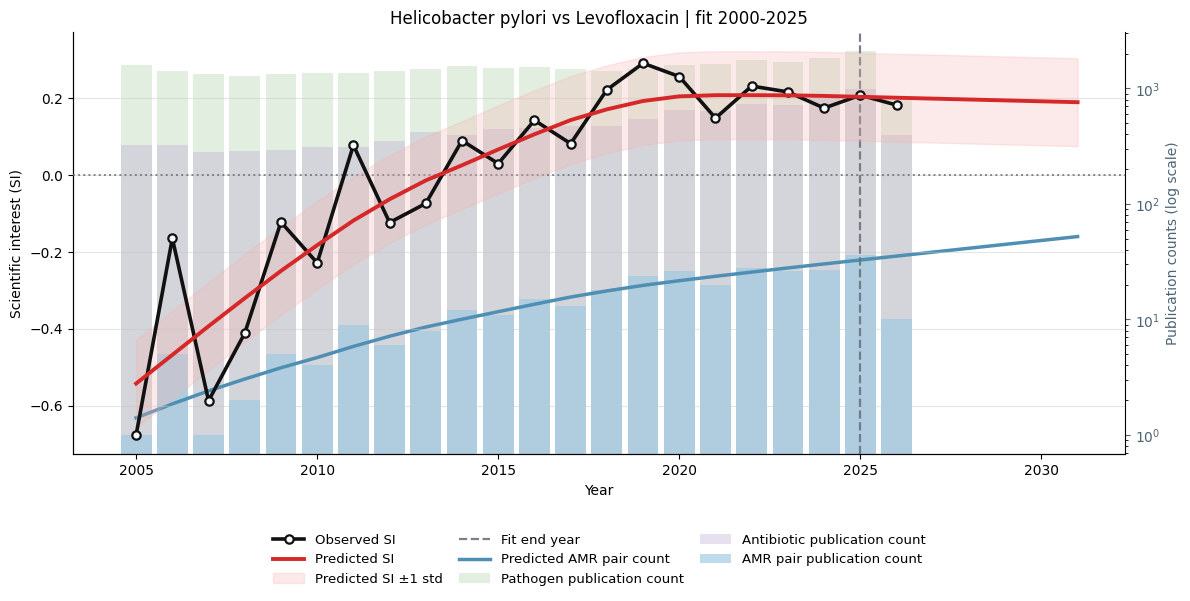

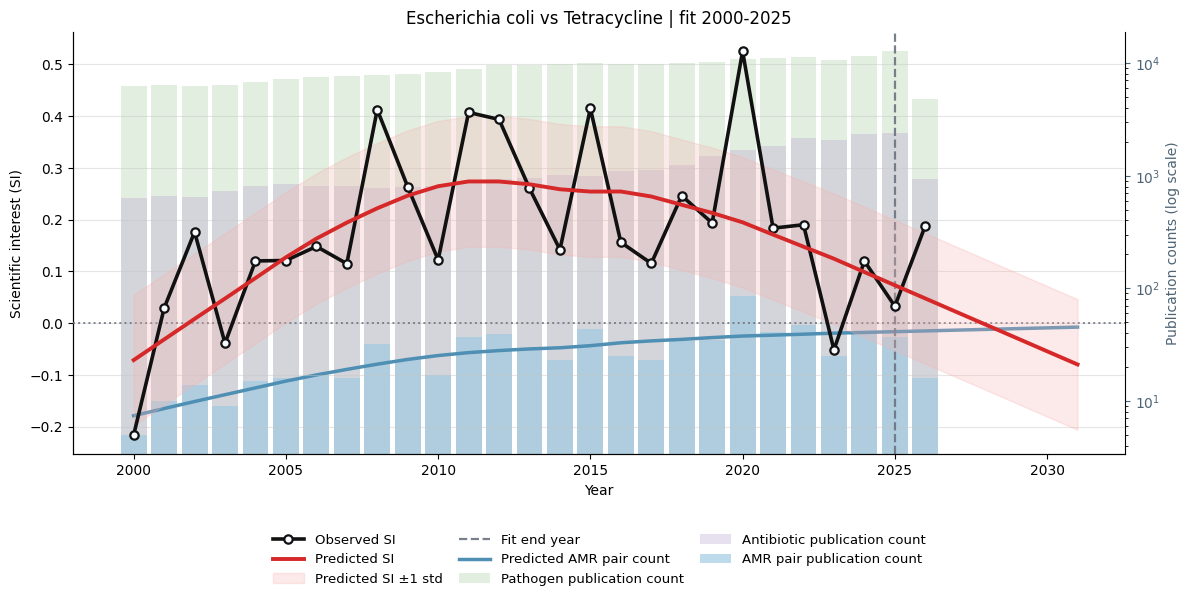

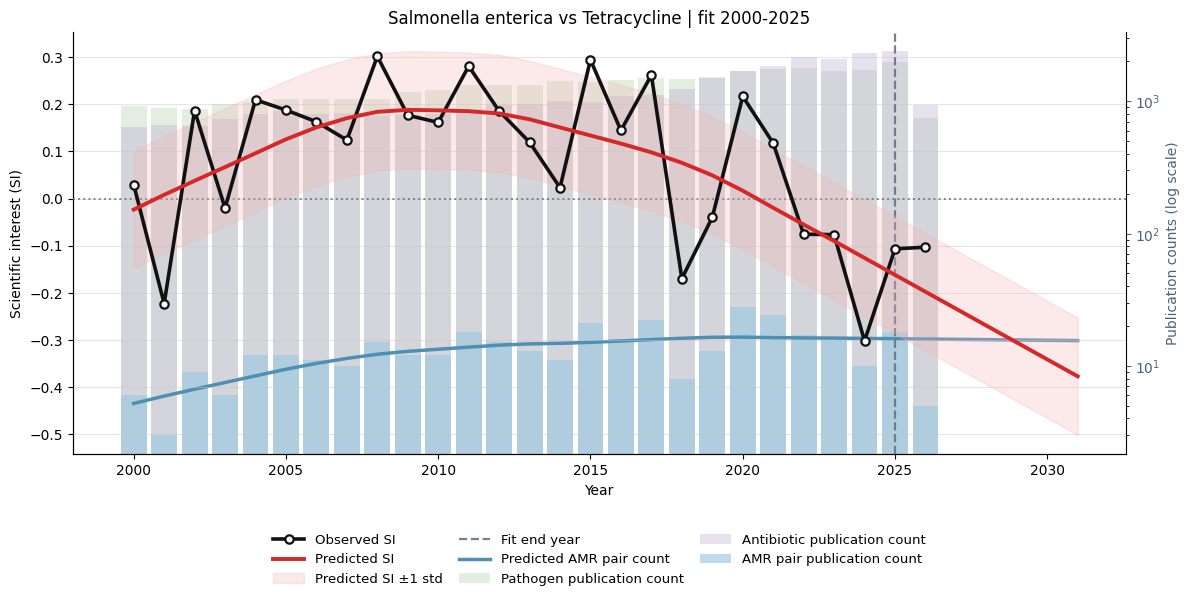

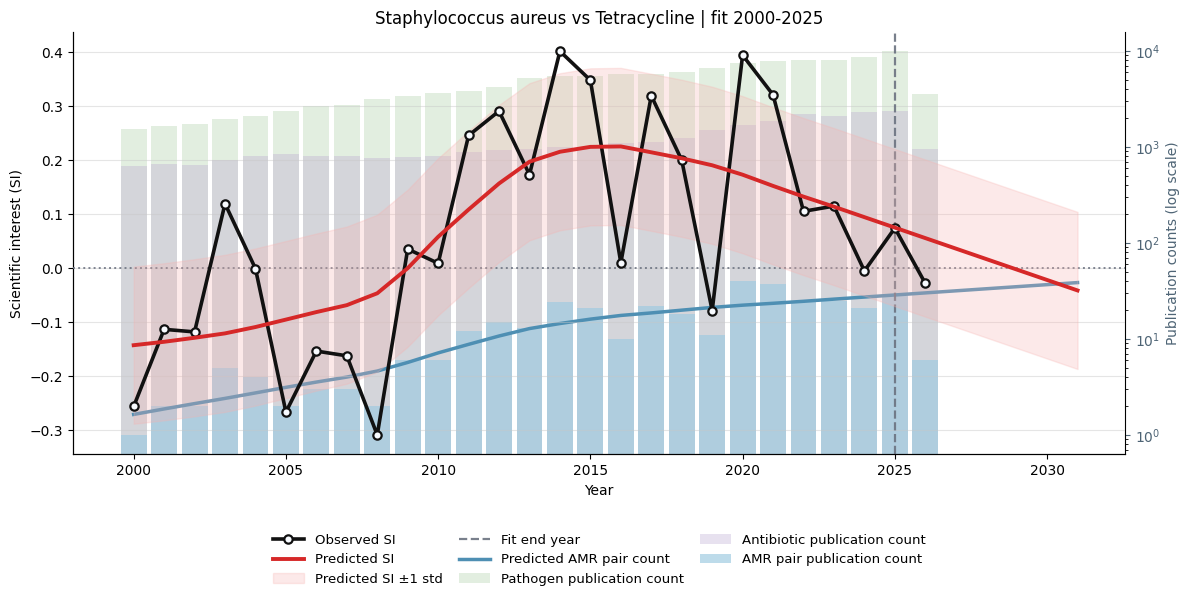

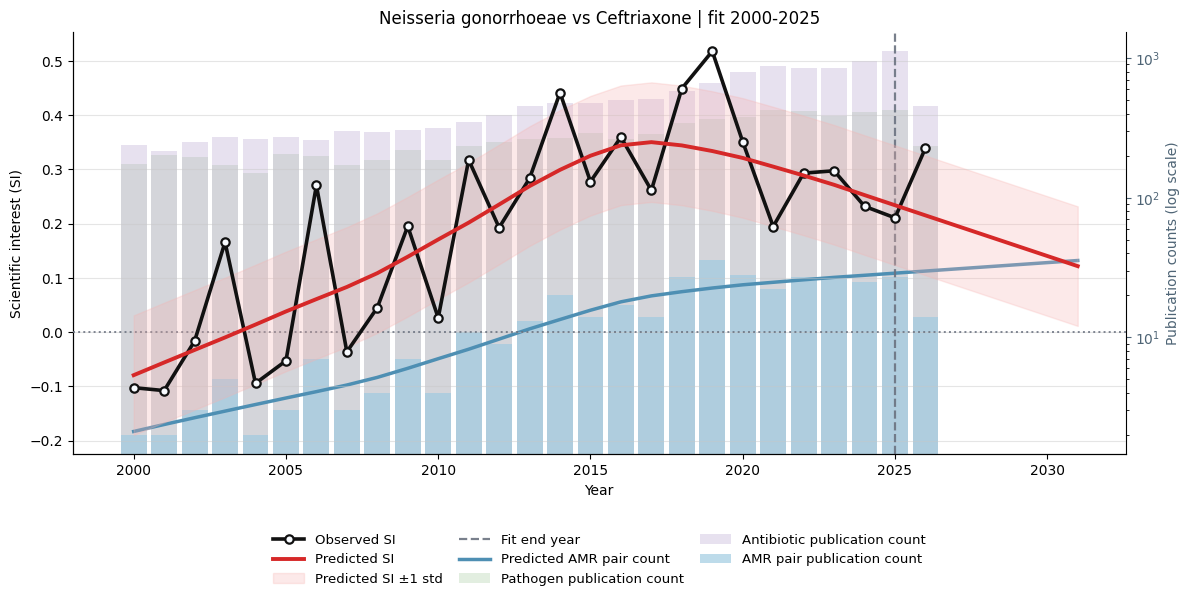

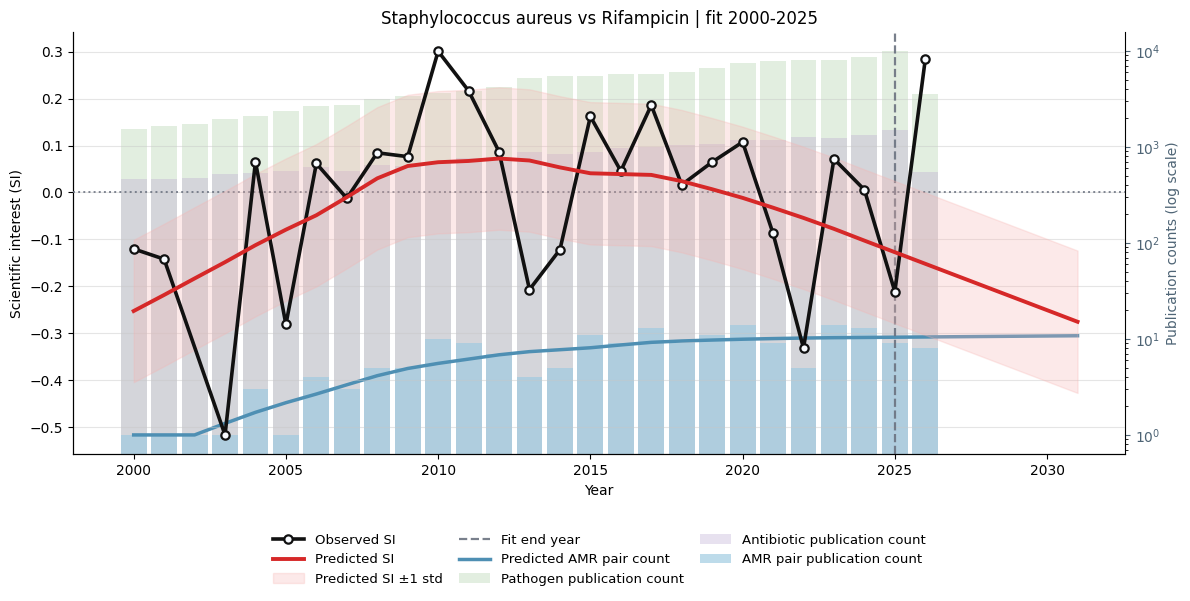

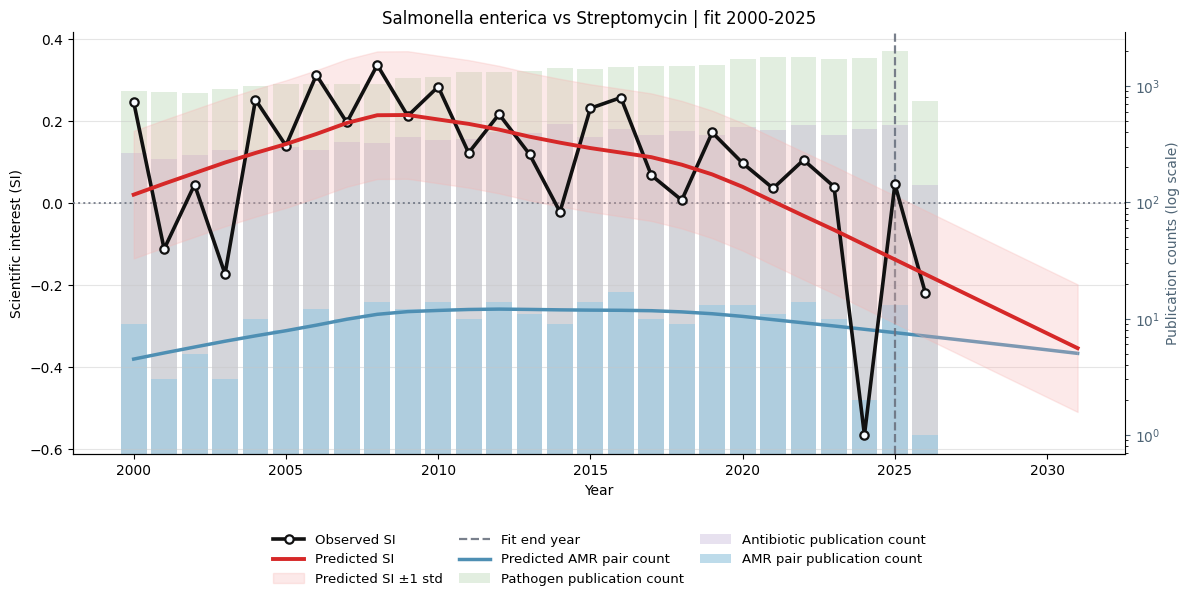

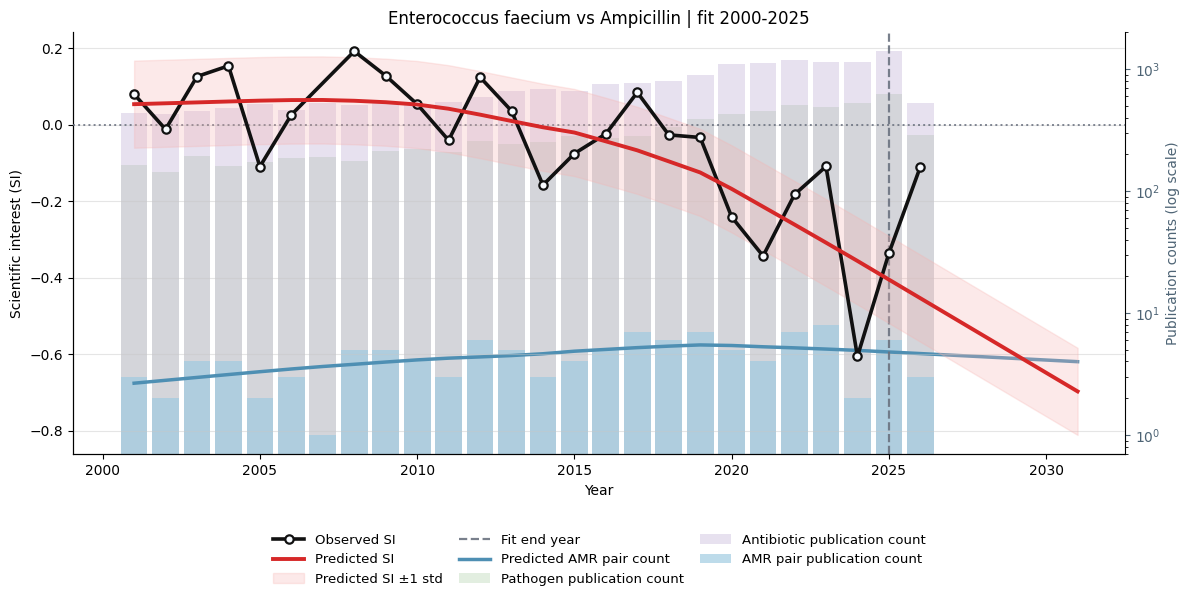

Saved 10 smoothed SI screen plots to /Users/f.costa/Code/Antimicrobial-Resistance/outputs/figures/concave_inverted_u_smoothed_si_plots


10

In [72]:
save_smoothed_si_screen_plots(
    screen_df=decreasing_smoothed_si_df,
    si_df=si_df,
    output_dir=DECREASING_SI_PLOT_DIR,
    fit_start_year=FIT_START_YEAR,
    curve_fit_end_year=CURVE_FIT_END_YEAR,
    num_future_years=NUM_FUTURE_YEARS,
    pathogen_background_df=pathogen_bg_df,
    antibiotic_background_df=antibiotic_bg_model_df,
    max_plots=SHAPE_SCREEN_PLOT_COUNT,
    figure_format=FIGURE_FORMAT,
    display_plots=DISPLAY_PLOTS,
)

save_smoothed_si_screen_plots(
    screen_df=most_convex_smoothed_si_df,
    si_df=si_df,
    output_dir=CONVEX_SI_PLOT_DIR,
    fit_start_year=FIT_START_YEAR,
    curve_fit_end_year=CURVE_FIT_END_YEAR,
    num_future_years=NUM_FUTURE_YEARS,
    pathogen_background_df=pathogen_bg_df,
    antibiotic_background_df=antibiotic_bg_model_df,
    max_plots=SHAPE_SCREEN_PLOT_COUNT,
    figure_format=FIGURE_FORMAT,
    display_plots=DISPLAY_PLOTS,
)

save_smoothed_si_screen_plots(
    screen_df=most_concave_smoothed_si_df,
    si_df=si_df,
    output_dir=CONCAVE_SI_PLOT_DIR,
    fit_start_year=FIT_START_YEAR,
    curve_fit_end_year=CURVE_FIT_END_YEAR,
    num_future_years=NUM_FUTURE_YEARS,
    pathogen_background_df=pathogen_bg_df,
    antibiotic_background_df=antibiotic_bg_model_df,
    max_plots=SHAPE_SCREEN_PLOT_COUNT,
    figure_format=FIGURE_FORMAT,
    display_plots=DISPLAY_PLOTS,
)
